# 세그멘테이션-1_픽셀 분류 · U-Net

> 🎯 **박스가 아니라 픽셀마다 정답을 맞히려면 모델의 출력 · 손실 · 지표는 어떻게 바뀌나?**

코드잇 Segmentation 강의(PDF 62쪽)의 Semantic Segmentation · FCN · U-Net 부분과 위클리 페이퍼 9(분할 부분)를 **4개 대단원 · 10개 섹션**으로 재구성하고, 마지막 **종합 실습**에서 U-Net의 skip 연결 효과를 직접 비교. 데이터는 내려받지 않고 노트북 안에서 그린 **도형 이미지 + 마스크**(배경 · 원 · 사각형 3클래스).

**수업 실행 코드가 없는 단원이라 코드는 모두 보강** · 개념 · 순서는 PDF와 위클리 9를 따르고, 코드 셀 · 실험 · 수치는 이 정리본에서 새로 작성 (섹션 제목의 <sub>개념 … · 코드 보강</sub> 표시)

## 이 노트북을 끝내면 답할 수 있어야 하는 질문

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">대단원</th>
<th style="text-align: left;">질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><strong>1. 분할 문제 정의</strong></td>
<td style="text-align: left;">분류 · 탐지 · 분할의 출력은 어떻게 다르고, 정답 마스크는 어떤 모양 · 자료형인가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>2. 픽셀 손실 · 업샘플링 · FCN</strong></td>
<td style="text-align: left;">픽셀마다 손실을 어떻게 구하고, 줄어든 지도를 어떻게 다시 키우는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>3. U-Net</strong></td>
<td style="text-align: left;">인코더-디코더를 지나며 모양이 어떻게 바뀌고, skip 연결은 무엇을 되살리는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>4. 평가 지표 · 손실</strong></td>
<td style="text-align: left;">픽셀 정확도 · mIoU · Dice, CrossEntropy · Dice 손실은 작은 클래스를 어떻게 다루는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>5. 종합 실습</strong></td>
<td style="text-align: left;">같은 조건에서 skip이 있는 U-Net과 없는 U-Net은 어디서 차이가 나는가?</td>
</tr>
</tbody>
</table>

## 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 분할 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;"><sub>개념 PDF · 위클리 · 코드 보강</sub></td>
<td style="text-align: left;">개념의 출처 (PDF 쪽 = 파일의 쪽 번호), 코드는 모두 보강</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">PDF 3~5쪽</td>
<td style="text-align: left;">Image Segmentation 정의 · Semantic / Instance / Panoptic · one-hot 라벨</td>
<td style="text-align: left;">1-1 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">PDF 7~8쪽</td>
<td style="text-align: left;">픽셀 · 패치 분류 아이디어, 출력 해상도 = 입력 해상도</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">PDF 10~15쪽</td>
<td style="text-align: left;">다운샘플링 · 업샘플링 (nearest · bed of nails · max unpooling · bilinear · 전치 합성곱)</td>
<td style="text-align: left;">2-2</td>
</tr>
<tr>
<td style="text-align: left;">PDF 16~28쪽</td>
<td style="text-align: left;">FCN (합성곱화 · 1×1 합성곱 · 업샘플링 · skip · 픽셀 CE · 장단점)</td>
<td style="text-align: left;">2-1 · 2-3 · 3-2</td>
</tr>
<tr>
<td style="text-align: left;">PDF 29~42쪽</td>
<td style="text-align: left;">U-Net (대칭 구조 · skip · overlap-tile · mirroring · 증강 · 경계 가중 CE · 장단점)</td>
<td style="text-align: left;">3-1 · 3-2 · 2-1</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q1</td>
<td style="text-align: left;">분류 vs 분할 출력, 픽셀 정확도 vs mIoU, Dice</td>
<td style="text-align: left;">1-1 · 1-2 · 4-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q2</td>
<td style="text-align: left;">FCN 정정 (합성곱화 · 전치 합성곱 · skip), 체커보드 무늬, FCN vs U-Net</td>
<td style="text-align: left;">2-2 · 2-3 · 3-2</td>
</tr>
<tr>
<td style="text-align: left;">PDF 43~62쪽</td>
<td style="text-align: left;">Instance Segmentation · Mask R-CNN · RoIAlign</td>
<td style="text-align: left;"><strong>세그멘테이션-2</strong>로</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q3 · Q4</td>
<td style="text-align: left;">GAN · Diffusion</td>
<td style="text-align: left;"><strong>생성모델-1</strong>로</td>
</tr>
<tr>
<td style="text-align: left;">미션 8</td>
<td style="text-align: left;">U-Net 축구 데이터</td>
<td style="text-align: left;">제외</td>
</tr>
</tbody>
</table>

### 다른 정리본과 겹치는 내용 (여기서는 참조만)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">자세한 설명</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">합성곱 · 풀링 · 특징 지도 크기 계산</td>
<td style="text-align: left;">CNN-1 · CNN-2</td>
</tr>
<tr>
<td style="text-align: left;">인코더 · 디코더 · 잠재 표현, <code>ConvTranspose2d</code> 기본 동작</td>
<td style="text-align: left;">오토인코더-1 · CNN-2</td>
</tr>
<tr>
<td style="text-align: left;">IoU (상자 기준) · NMS</td>
<td style="text-align: left;">객체탐지-1</td>
</tr>
</tbody>
</table>

## 전체 지도

### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">상자 대신 픽셀로 답하면 출력 · 정답 모양부터 바뀐다</td>
<td style="text-align: left;">분할 문제 정의</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">픽셀마다 손실을 매기고, 줄어든 지도를 다시 키워야 한다</td>
<td style="text-align: left;">픽셀 손실 · 업샘플링 · FCN</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">키우기만 하면 경계가 흐려져 고해상도 특징을 옆에서 건넨다</td>
<td style="text-align: left;">U-Net</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">배경이 대부분이라 픽셀 정확도로는 좋은 모델을 못 고른다</td>
<td style="text-align: left;">평가 지표 · 손실</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">1~4를 합쳐 skip 연결의 효과를 숫자와 그림으로 확인한다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

### 분할 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터</td>
<td style="text-align: left;">이미지 + 정답 마스크 준비</td>
<td style="text-align: left;">0장 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">② 출력 정하기</td>
<td style="text-align: left;">클래스 수 C, 출력 <code>(N, C, H, W)</code></td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;">③ 모델 구조</td>
<td style="text-align: left;">인코더 · 업샘플링 · skip · 1×1 머리</td>
<td style="text-align: left;">2-2 · 2-3 · 3장 · <strong>5장</strong></td>
</tr>
<tr>
<td style="text-align: left;">④ 손실</td>
<td style="text-align: left;">픽셀별 CE · Dice</td>
<td style="text-align: left;">2-1 · 4-2 · <strong>5장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑤ 학습</td>
<td style="text-align: left;">seed 고정 · 같은 조건</td>
<td style="text-align: left;"><strong>5장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑥ 평가</td>
<td style="text-align: left;">픽셀 정확도 · mIoU · Dice · 경계 정확도</td>
<td style="text-align: left;">4-1 · <strong>5장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑦ 시각화</td>
<td style="text-align: left;">정답 · 예측 · 틀린 픽셀 그림</td>
<td style="text-align: left;">1-1 · <strong>5장</strong></td>
</tr>
</tbody>
</table>

**굵은 5장** · 종합 실습이 ③ ~ ⑦ 을 한 번에 연결

---
## 0. 준비

라이브러리 · seed · 장치를 정하고, 실습 데이터(도형 이미지 + 마스크)를 노트북 안에서 그림. 내려받는 파일 없음.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">내용</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">재현성</td>
<td style="text-align: left;"><code>torch.manual_seed</code> · <code>cudnn.deterministic = True</code> · <code>cudnn.benchmark = False</code>, DataLoader 섞기도 seed 고정</td>
</tr>
<tr>
<td style="text-align: left;">장치</td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>, 없으면 <code>cpu</code> (CPU에서도 그대로 실행, 5장 학습이 모델당 수 분)</td>
</tr>
<tr>
<td style="text-align: left;">이미지</td>
<td style="text-align: left;">64×64 RGB, 배경 그러데이션 + 잡음, 도형 2 ~ 4개 (색은 무작위 → 색이 아니라 <strong>모양</strong>으로 구분해야 함)</td>
</tr>
<tr>
<td style="text-align: left;">마스크</td>
<td style="text-align: left;"><code>(64, 64)</code> 정수, 0 배경 · 1 원 · 2 사각형, 겹치면 나중에 그린 도형이 위</td>
</tr>
<tr>
<td style="text-align: left;">분량</td>
<td style="text-align: left;">학습 600장 (seed 0) · 검증 100장 (seed 1)</td>
</tr>
</tbody>
</table>

In [1]:
# [보강] 라이브러리 · 재현성 · 장치 설정
import os
import random
import time

if "KMP_DUPLICATE_LIB_OK" not in os.environ:  # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # numpy · torch OpenMP 중복

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from scipy import ndimage  # ndimage.label → 붙어 있는 덩어리 번호
from torch import nn

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # GPU 연산도 같은 결과
    torch.backends.cudnn.benchmark = False  # 매번 같은 알고리즘 선택


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)


# 그림 한글 글꼴 (있을 때만) · 마스크 색 (배경 · 원 · 사각형)
fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
CMAP = ListedColormap(["#20232a", "#f2b134", "#3ba3ec"])  # 0 · 1 · 2
CLASSES = ["배경", "원", "사각형"]

torch 2.11.0+cu128 | device: cuda


X_train: (600, 3, 64, 64) torch.float32
Y_train: (600, 64, 64) torch.int64
X_val: (100, 3, 64, 64) | Y_val: (100, 64, 64)
클래스 비율: {'배경': 0.843, '원': 0.083, '사각형': 0.073}


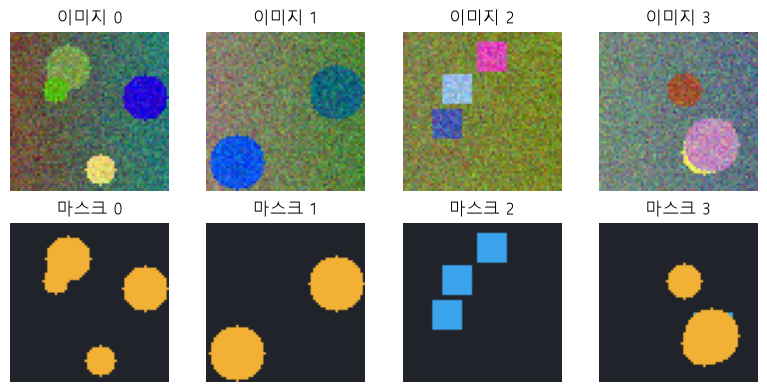

In [2]:
# [보강] 도형 그리기: 이미지 · 의미 마스크 · 인스턴스 마스크를 함께 칠함
H = W = 64
YY, XX = np.mgrid[0:H, 0:W]  # 픽셀마다 (행, 열) 좌표


def paint(img, sem, inst, cls, cy, cx, size, color, k, rng):
    if cls == 1:  # 원: 중심에서 거리 ≤ 반지름
        region = (YY - cy) ** 2 + (XX - cx) ** 2 <= size ** 2
    else:  # 사각형: 왼쪽 위 (cy, cx) · 한 변 size
        region = ((YY >= cy) & (YY < cy + size)
                  & (XX >= cx) & (XX < cx + size))
    noise = rng.normal(0, 0.08, (3, region.sum()))
    img[:, region] = np.asarray(color)[:, None] + noise  # 색 + 잡음
    sem[region] = cls  # 의미 마스크: 클래스 번호
    inst[region] = k  # 인스턴스 마스크: 개체 번호


def make_sample(rng):
    base = rng.uniform(0.2, 0.6, 3)[:, None, None]  # 배경 밝기
    tilt = rng.uniform(-0.3, 0.3, 3)[:, None, None]  # 좌우 그러데이션
    img = base + tilt * (XX / W) + rng.normal(0, 0.08, (3, H, W))
    sem = np.zeros((H, W), np.int64)
    inst = np.zeros((H, W), np.int64)
    for k in range(1, rng.integers(2, 5) + 1):  # 도형 2 ~ 4개
        cls = rng.integers(1, 3)  # 1 원 · 2 사각형
        color = rng.uniform(0, 1, 3)  # 색은 클래스와 무관
        if cls == 1:
            r = rng.integers(5, 13)
            cy, cx = rng.integers(r, H - r), rng.integers(r, W - r)
            paint(img, sem, inst, 1, cy, cx, r, color, k, rng)
        else:
            s = rng.integers(8, 22)
            cy, cx = rng.integers(0, H - s), rng.integers(0, W - s)
            paint(img, sem, inst, 2, cy, cx, s, color, k, rng)
    return np.clip(img, 0, 1).astype(np.float32), sem, inst


def make_dataset(n, seed):
    rng = np.random.default_rng(seed)
    imgs, masks = zip(*[make_sample(rng)[:2] for _ in range(n)])
    return torch.tensor(np.stack(imgs)), torch.tensor(np.stack(masks))


# 학습 600장 · 검증 100장 (seed가 달라 겹치지 않음)
X_train, Y_train = make_dataset(600, seed=0)
X_val, Y_val = make_dataset(100, seed=1)
print("X_train:", tuple(X_train.shape), X_train.dtype)
print("Y_train:", tuple(Y_train.shape), Y_train.dtype)
print("X_val:", tuple(X_val.shape), "| Y_val:", tuple(Y_val.shape))
ratio = torch.bincount(Y_train.flatten(), minlength=3) / Y_train.numel()
print("클래스 비율:", {c: round(r, 3) for c, r in
                  zip(CLASSES, ratio.tolist())})


# 앞 4장: 이미지 위 · 마스크 아래
fig, ax = plt.subplots(2, 4, figsize=(8, 4))
for i in range(4):
    ax[0, i].imshow(X_train[i].permute(1, 2, 0))  # CHW → HWC
    ax[1, i].imshow(Y_train[i], cmap=CMAP, vmin=0, vmax=2)
    ax[0, i].set_title(f"이미지 {i}")
    ax[1, i].set_title(f"마스크 {i}")
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
plt.show()

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>X_train: (600, 3, 64, 64) torch.float32</code></td>
<td style="text-align: left;">이미지 <code>(N, C, H, W)</code>, 0 ~ 1 실수</td>
</tr>
<tr>
<td style="text-align: left;"><code>Y_train: (600, 64, 64) torch.int64</code></td>
<td style="text-align: left;">마스크 <code>(N, H, W)</code>, 채널 축 없는 정수 (1-3)</td>
</tr>
<tr>
<td style="text-align: left;"><code>X_val: (100, 3, 64, 64) &#124; Y_val: (100, 64, 64)</code></td>
<td style="text-align: left;">검증은 다른 seed로 만든 100장</td>
</tr>
<tr>
<td style="text-align: left;"><code>클래스 비율: {'배경': 0.843, '원': 0.083, '사각형': 0.073}</code></td>
<td style="text-align: left;">배경이 84% → 전부 배경이라고 찍어도 픽셀 정확도 84% (4장의 이유)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 실행할 때마다 다른 데이터가 나오면 비교 실험이 불가 → `default_rng(seed)`로 데이터까지 고정

---
## 1. 분할 문제 정의

> **연결** · 객체탐지-1 ~ 3에서는 개체를 **상자**로 답했다 → 상자 안에는 배경이 섞이고 경계를 모름. 픽셀마다 답하려면 출력 · 정답 마스크의 모양부터 바뀜

**흐름 위치** · ① 데이터 · ② 출력 정하기 — 작업 고르기, 출력 `(N, C, H, W)`, 정답 마스크 `(N, H, W)`

### 1-1. `A` 네 가지 비전 작업의 출력 · `분류` · `탐지` · `의미 분할` · `인스턴스 분할` <sub>개념 PDF 3~4 · 44~45쪽 · 위클리 9 Q1 · 코드 보강</sub>

> 🎯 **같은 사진이라도 분류 · 탐지 · 의미 분할 · 인스턴스 분할은 출력이 어떻게 다르고, 각각 무엇까지 답할 수 있는가?**

💡 **쉽게 말하면** 분류는 **사진에 붙이는 이름표 하나**, 탐지는 **물건마다 두른 상자**, 의미 분할은 **픽셀마다 칠한 색칠 공부**, 인스턴스 분할은 **물건마다 따로 오려 낸 스티커**.

**실행 흐름** · 원 2개(붙임) + 사각형 1개 장면 → ① 분류 · ② 탐지 · ③ 의미 분할 · ④ 인스턴스 출력 만들기 → 값 개수 · 원 개수 비교 → 그림

**먼저 예측** · 원 2개가 붙어 있을 때, 의미 분할 마스크만으로 원이 몇 개인지 셀 수 있을까? — 답은 코드 실행 결과 아래에

① 분류      출력: [1, 1] → 값 2 개
② 탐지      출력: [(9, 11, 26, 29, 1), (26, 11, 44, 29, 1), (30, 38, 47, 55, 2)] → 값 15 개
③ 의미 분할 출력: (64, 64) → 값 4096 개 | 원 덩어리 수: 1
④ 인스턴스  출력: (3, 64, 64) → 원 개수: 2


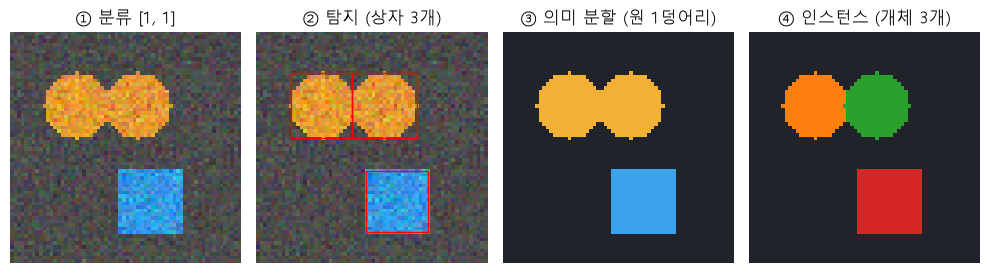

In [3]:
# [보강] 같은 장면 1장: 원 2개를 붙여 그리고 사각형 1개
rng = np.random.default_rng(7)
img = np.full((3, H, W), 0.3) + rng.normal(0, 0.05, (3, H, W))
sem = np.zeros((H, W), np.int64)
inst = np.zeros((H, W), np.int64)
paint(img, sem, inst, 1, 20, 18, 9, (0.9, 0.6, 0.2), 1, rng)  # 원 A
paint(img, sem, inst, 1, 20, 35, 9, (0.9, 0.6, 0.2), 2, rng)  # 원 B
paint(img, sem, inst, 2, 38, 30, 18, (0.2, 0.6, 0.9), 3, rng)


# ① 분류 (다중 라벨): 어떤 클래스가 있나 → 값 2개
present = [int((sem == c).any()) for c in (1, 2)]
print("① 분류      출력:", present, "→ 값", len(present), "개")


# ② 탐지: 개체마다 상자 (x1, y1, x2, y2) + 클래스
boxes = []
for k in range(1, inst.max() + 1):
    ys, xs = np.where(inst == k)  # 개체 k의 픽셀 좌표
    cls = int(sem[ys[0], xs[0]])
    boxes.append((int(xs.min()), int(ys.min()),
                  int(xs.max()), int(ys.max()), cls))
print("② 탐지      출력:", boxes, "→ 값", len(boxes) * 5, "개")


# ③ 의미 분할: 픽셀마다 클래스 → 원이 몇 덩어리로 보이나
_, n_blob = ndimage.label(sem == 1)  # 상하좌우로 이어진 덩어리 수
print("③ 의미 분할 출력:", sem.shape, "→ 값", sem.size, "개",
      "| 원 덩어리 수:", n_blob)


# ④ 인스턴스 분할: 개체마다 마스크 1장
inst_masks = np.stack([inst == k for k in range(1, inst.max() + 1)])
print("④ 인스턴스  출력:", inst_masks.shape, "→ 원 개수:",
      sum(b[-1] == 1 for b in boxes))


# 네 가지 출력을 한 그림으로
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
ax[0].imshow(np.clip(img, 0, 1).transpose(1, 2, 0))
ax[0].set_title(f"① 분류 {present}")
ax[1].imshow(np.clip(img, 0, 1).transpose(1, 2, 0))
for x1, y1, x2, y2, c in boxes:
    ax[1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                  fill=False, color="red"))
ax[1].set_title("② 탐지 (상자 3개)")
ax[2].imshow(sem, cmap=CMAP, vmin=0, vmax=2)
ax[2].set_title("③ 의미 분할 (원 1덩어리)")
inst_cmap = ListedColormap(["#20232a", "#ff7f0e", "#2ca02c", "#d62728"])
ax[3].imshow(inst, cmap=inst_cmap, vmin=0, vmax=3)  # 개체마다 다른 색
ax[3].set_title("④ 인스턴스 (개체 3개)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**예측 정답** · 없음 — 원 픽셀이 **한 덩어리**(덩어리 수 1)로 이어져 1개처럼 보임, 개수는 인스턴스 분할이 답함

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>① 분류      출력: [1, 1] → 값 2 개</code></td>
<td style="text-align: left;">원 · 사각형이 <strong>있다</strong>는 것만, 위치 · 개수 · 경계는 없음</td>
</tr>
<tr>
<td style="text-align: left;"><code>② 탐지      출력: [(9, 11, 26, 29, 1), (26, 11, 44, 29, 1), (30, 38, 47, 55, 2)] → 값 15 개</code></td>
<td style="text-align: left;">상자 3개 × (좌표 4 + 클래스 1), 원 A · B 상자가 겹치고 상자 안에 배경도 섞임</td>
</tr>
<tr>
<td style="text-align: left;"><code>③ 의미 분할 출력: (64, 64) → 값 4096 개 &#124; 원 덩어리 수: 1</code></td>
<td style="text-align: left;">64 × 64 = 4096 픽셀마다 클래스 번호, 붙은 원 2개가 한 덩어리 → 개수를 셀 수 없음</td>
</tr>
<tr>
<td style="text-align: left;"><code>④ 인스턴스  출력: (3, 64, 64) → 원 개수: 2</code></td>
<td style="text-align: left;">개체 3개 × 마스크 1장씩 → 붙어 있어도 원 2개를 구분</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류</td>
<td style="text-align: left;">이미지 전체에 라벨 (다중 라벨이면 클래스마다 있음 · 없음)</td>
<td style="text-align: left;">무엇이 있는지만 알면 될 때 (정상 · 불량 판정)</td>
</tr>
<tr>
<td style="text-align: left;">객체 탐지</td>
<td style="text-align: left;">개체마다 <strong>상자</strong> + 클래스 + 신뢰도, 상자 안 배경도 포함</td>
<td style="text-align: left;">위치 · 개수가 필요하고 경계는 대략이면 될 때 (CCTV 계수)</td>
</tr>
<tr>
<td style="text-align: left;">의미 분할 (Semantic)</td>
<td style="text-align: left;">픽셀마다 <strong>클래스</strong>, 같은 클래스 개체끼리는 구분 X</td>
<td style="text-align: left;">영역 · 넓이 · 경계가 필요할 때 (도로 영역, 병변 범위)</td>
</tr>
<tr>
<td style="text-align: left;">인스턴스 분할 (Instance)</td>
<td style="text-align: left;">개체마다 <strong>마스크</strong> 1장, 같은 클래스도 개체별로 구분</td>
<td style="text-align: left;">개체별 모양 · 개수가 모두 필요할 때 (세포 하나하나)</td>
</tr>
<tr>
<td style="text-align: left;">파놉틱 분할 (Panoptic)</td>
<td style="text-align: left;">배경(stuff)은 의미 분할, 물체(thing)는 인스턴스 분할을 한 지도로</td>
<td style="text-align: left;">장면 전체를 빠짐없이 이해할 때 (자율주행) → 세그멘테이션-2</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 의미 분할 결과로 "덩어리 수 = 개체 수"라고 세기 — 붙어 있거나 겹친 개체는 하나로 합쳐짐

> ✅ **한 줄 정리** · 분류는 무엇이 있는지, 탐지는 어디에 몇 개인지(상자), 의미 분할은 픽셀마다 무엇인지, 인스턴스 분할은 개체마다 정확히 어느 픽셀인지를 답한다.

**딥러닝 코드에서는** · 자율주행의 도로 영역은 의미 분할, 세포 하나하나 세기는 인스턴스 분할 — 문제의 답이 "영역"인지 "개체"인지로 모델을 고름

### 1-2. `A` 출력 모양 · `(N, C)` · `(N, C, H, W)` · `argmax(dim=1)` <sub>개념 PDF 7~8쪽 · 위클리 9 Q1 · 코드 보강</sub>

> 🎯 **분류 모델과 분할 모델의 출력 모양은 어떻게 다르고, 예측 마스크는 어느 축에서 고르는가?**

💡 **쉽게 말하면** 분류는 **사진 한 장에 점수표 한 장**, 분할은 **픽셀마다 점수표 한 장**. 점수표에서 가장 높은 칸을 고르는 축(클래스 축)은 둘 다 1번.

**실행 흐름** · 이미지 4장 → 분류 모델 (N, C) · 분할 모델 (N, C, H, W) → argmax(dim=1) → dim 실수 2가지 → 픽셀 확률 합

**먼저 예측** · 분할 출력 `(4, 3, 64, 64)`에 `argmax(dim=1)`을 하면 모양은? — 답은 코드 실행 결과 아래에

In [4]:
# [보강] 같은 이미지 4장을 분류 · 분할 모델에 넣기
x = X_train[:4]  # 이미지 4장 (N, 3, 64, 64)


# 분류 모델: 합성곱 → 평탄화 → Linear → (N, C)
classifier = nn.Sequential(
    nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),  # (N, 8, 64, 64) → (N, 8, 1, 1)
    nn.Flatten(),  # → (N, 8)
    nn.Linear(8, 3))  # → (N, 3)


# 분할 모델: 합성곱만 → (N, C, H, W)
segmenter = nn.Sequential(
    nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),
    nn.Conv2d(8, 3, 1))  # 1×1 합성곱: 픽셀마다 점수 3개


cls_out, seg_out = classifier(x), segmenter(x)
print("분류 출력:", tuple(cls_out.shape),
      "| 분할 출력:", tuple(seg_out.shape))


# 클래스 축(dim=1)에서 가장 큰 번호 → 예측
print("분류 예측:", tuple(cls_out.argmax(dim=1).shape),
      "| 분할 예측:", tuple(seg_out.argmax(dim=1).shape))


# 흔한 실수: dim을 빼먹거나 0으로
print("argmax() :", tuple(seg_out.argmax().shape), "← 전체에서 1개")
print("argmax(0):", tuple(seg_out.argmax(dim=0).shape), "← 배치 축")


# 픽셀 하나의 확률 합 = 1 (softmax도 dim=1)
prob = seg_out.softmax(dim=1)
print("픽셀 (0, 10, 10) 확률 합:", round(prob[0, :, 10, 10].sum().item(), 4))

분류 출력: (4, 3) | 분할 출력: (4, 3, 64, 64)
분류 예측: (4,) | 분할 예측: (4, 64, 64)
argmax() : () ← 전체에서 1개
argmax(0): (3, 64, 64) ← 배치 축
픽셀 (0, 10, 10) 확률 합: 1.0


**예측 정답** · `(4, 64, 64)` — 클래스 축(3)이 사라지고 픽셀마다 번호 1개 = 예측 마스크

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>분류 출력: (4, 3) &#124; 분할 출력: (4, 3, 64, 64)</code></td>
<td style="text-align: left;">이미지마다 점수 3개 vs 픽셀마다 점수 3개</td>
</tr>
<tr>
<td style="text-align: left;"><code>분류 예측: (4,) &#124; 분할 예측: (4, 64, 64)</code></td>
<td style="text-align: left;">dim=1을 고르면 이미지당 번호 1개 · 픽셀당 번호 1개(마스크)</td>
</tr>
<tr>
<td style="text-align: left;"><code>argmax() : () ← 전체에서 1개</code></td>
<td style="text-align: left;">dim을 빼면 모든 값 중 최댓값 위치 하나 → 마스크가 아님</td>
</tr>
<tr>
<td style="text-align: left;"><code>argmax(0): (3, 64, 64) ← 배치 축</code></td>
<td style="text-align: left;">에러 없이 모양만 틀림 → 이미지 4장 중 하나를 고른 꼴</td>
</tr>
<tr>
<td style="text-align: left;"><code>픽셀 (0, 10, 10) 확률 합: 1.0</code></td>
<td style="text-align: left;">softmax(dim=1) → 픽셀마다 클래스 확률의 합이 1</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>(N, C)</code></td>
<td style="text-align: left;">이미지마다 점수 C개 → <code>argmax(dim=1)</code> → <code>(N,)</code></td>
<td style="text-align: left;">분류 모델 출력</td>
</tr>
<tr>
<td style="text-align: left;"><code>(N, C, H, W)</code></td>
<td style="text-align: left;">픽셀마다 점수 C개 → <code>argmax(dim=1)</code> → <code>(N, H, W)</code> 마스크</td>
<td style="text-align: left;">분할 모델 출력 (클래스 축은 항상 1번)</td>
</tr>
<tr>
<td style="text-align: left;"><code>argmax()</code> · <code>argmax(dim=0)</code></td>
<td style="text-align: left;">전체에서 1개 · 배치 축에서 고름 (에러 없이 틀림)</td>
<td style="text-align: left;">쓰지 않음 → 클래스 축 <code>dim=1</code> 고정</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · `argmax(dim=0)`은 에러가 나지 않음 → 예측 마스크 모양이 `(N, H, W)`인지 항상 확인

> ✅ **한 줄 정리** · 분류 출력은 (N, C), 분할 출력은 (N, C, H, W)이며, 둘 다 클래스 축 dim=1에서 argmax · softmax를 한다.

**딥러닝 코드에서는** · `pred = model(x).argmax(dim=1)` → `(N, H, W)` 마스크를 정답 마스크와 바로 비교

### 1-3. `A` 마스크 자료형 · `long (N, H, W)` · `one-hot (N, C, H, W)` <sub>개념 PDF 5쪽 · 위클리 9 Q1 · 코드 보강</sub>

> 🎯 **정답 마스크는 어떤 모양 · 자료형으로 만들어야 CrossEntropy에 바로 들어가는가?**

💡 **쉽게 말하면** 정답 마스크는 **픽셀마다 클래스 번호를 적은 정수 지도**. one-hot은 같은 정보를 **클래스마다 0/1 지도 한 장씩** 펼친 것.

**실행 흐름** · 정답 마스크 확인 → long 마스크 CE → one-hot으로 펼쳐 CE → 채널 축 실수 · float 실수

**먼저 예측** · 마스크를 `(N, 1, H, W)`처럼 채널 축을 붙여 넣으면? — 답은 코드 실행 결과 아래에

In [5]:
# [보강] 무작위 점수(모델 출력 흉내)와 정답 마스크 4장
logits = torch.randn(4, 3, 64, 64)  # 모델 출력 (N, C, H, W)
target = Y_train[:4]  # 정답 마스크
print("정답 마스크:", tuple(target.shape), target.dtype,
      "| 값 종류:", target.unique().tolist())


# 방식 1: 정수 마스크 (N, H, W) long → CrossEntropy 기본 입력
loss_long = F.cross_entropy(logits, target)
print("long 마스크 loss  :", round(loss_long.item(), 4))


# 방식 2: one-hot (N, C, H, W) float → 클래스 확률로 받음
onehot = F.one_hot(target, num_classes=3)  # (N, H, W, C)
onehot = onehot.permute(0, 3, 1, 2).float()  # → (N, C, H, W)
loss_onehot = F.cross_entropy(logits, onehot)
print("one-hot", tuple(onehot.shape), "loss:", round(loss_onehot.item(), 4))


# 흔한 실수 1: 마스크에 채널 축 (N, 1, H, W)
try:
    F.cross_entropy(logits, target.unsqueeze(1))
except RuntimeError as e:
    print("(N, 1, H, W) →", type(e).__name__, "→ squeeze(1)로 해결")


# 흔한 실수 2: 정수 마스크를 float로
try:
    F.cross_entropy(logits, target.float())
except RuntimeError as e:
    print("float (N, H, W) →", type(e).__name__, "→ .long()으로 해결")

정답 마스크: (4, 64, 64) torch.int64 | 값 종류: [0, 1, 2]
long 마스크 loss  : 1.391
one-hot (4, 3, 64, 64) loss: 1.391
(N, 1, H, W) → RuntimeError → squeeze(1)로 해결
float (N, H, W) → RuntimeError → .long()으로 해결


**예측 정답** · `RuntimeError` — CE는 `(N, H, W)` 정수 마스크를 기대 → `squeeze(1)`

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>정답 마스크: (4, 64, 64) torch.int64 &#124; 값 종류: [0, 1, 2]</code></td>
<td style="text-align: left;">채널 축 없음 · 정수(long) · 값 = 클래스 번호</td>
</tr>
<tr>
<td style="text-align: left;"><code>long 마스크 loss  : 1.391</code></td>
<td style="text-align: left;">무작위 점수에 대한 손실 (학습 전 수준)</td>
</tr>
<tr>
<td style="text-align: left;"><code>one-hot (4, 3, 64, 64) loss: 1.391</code></td>
<td style="text-align: left;">같은 값 → one-hot을 클래스 확률로 주면 같은 계산</td>
</tr>
<tr>
<td style="text-align: left;"><code>(N, 1, H, W) → RuntimeError → squeeze(1)로 해결</code></td>
<td style="text-align: left;">흑백 이미지처럼 읽은 마스크에 흔한 채널 축</td>
</tr>
<tr>
<td style="text-align: left;"><code>float (N, H, W) → RuntimeError → .long()으로 해결</code></td>
<td style="text-align: left;">float 정답은 확률 지도 <code>(N, C, H, W)</code>로 읽으려 해 모양 불일치</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">정수 마스크 <code>(N, H, W)</code> long</td>
<td style="text-align: left;">픽셀 값 = 클래스 번호, 메모리 C배 적음</td>
<td style="text-align: left;"><code>CrossEntropyLoss</code> 기본 입력 · 데이터 저장 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">one-hot <code>(N, C, H, W)</code> float</td>
<td style="text-align: left;">클래스마다 0/1 지도, 모델 출력과 같은 모양</td>
<td style="text-align: left;">Dice 손실 계산 (4-2) · 클래스 확률(soft label)을 줄 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>(N, 1, H, W)</code> 마스크</td>
<td style="text-align: left;">채널 축 1이 남은 모양 → CE에서 에러</td>
<td style="text-align: left;"><code>squeeze(1)</code> 해서 <code>(N, H, W)</code>로 바꾼 뒤 사용</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 마스크를 PNG로 읽은 뒤 `/ 255`로 정규화하면 클래스 번호가 0 ~ 1 실수로 깨짐 → 마스크는 정규화 금지

> ✅ **한 줄 정리** · CrossEntropy의 정답은 (N, H, W) long 마스크이고, one-hot (N, C, H, W)는 Dice 손실처럼 클래스별 지도가 필요할 때 만든다.

**딥러닝 코드에서는** · `Dataset.__getitem__`에서 `mask = torch.as_tensor(np.array(m), dtype=torch.long)` → 채널 축 없이 반환

#### 1장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>ndimage.label()</code></td>
<td style="text-align: left;">scipy</td>
<td style="text-align: left;">붙어 있는 덩어리에 번호 (의미 분할로 개수 세기의 한계 확인)</td>
</tr>
<tr>
<td style="text-align: left;"><code>argmax(dim=1)</code> · <code>softmax(dim=1)</code></td>
<td style="text-align: left;">torch.Tensor</td>
<td style="text-align: left;">클래스 축에서 예측 번호 · 확률</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.AdaptiveAvgPool2d</code> · <code>nn.Flatten</code> · <code>nn.Linear</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">분류 머리 (공간 정보를 없앰)</td>
</tr>
<tr>
<td style="text-align: left;"><code>F.one_hot()</code> · <code>permute()</code></td>
<td style="text-align: left;">torch.nn.functional · torch.Tensor</td>
<td style="text-align: left;">정수 마스크 → 클래스별 0/1 지도</td>
</tr>
<tr>
<td style="text-align: left;"><code>F.cross_entropy(logits, mask)</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">(N, C, H, W) 점수 · (N, H, W) long 정답</td>
</tr>
</tbody>
</table>

---
## 2. 픽셀 손실 · 업샘플링 · FCN

> **연결** · 1장에서 출력 모양을 정했다 → 픽셀마다 손실을 매기는 법, 합성곱으로 줄어든 지도를 입력 크기로 다시 키우는 법, 분류 CNN을 분할 모델로 바꾸는 법(FCN)

**흐름 위치** · ③ 모델 구조 · ④ 손실 — 픽셀 CE, 업샘플링 방법, 1×1 합성곱 머리

### 2-1. `A` 픽셀마다 교차 엔트로피 · `F.cross_entropy` · `ignore_index` <sub>개념 PDF 26 · 41쪽 · 위클리 9 Q1 · 코드 보강</sub>

> 🎯 **분할의 CrossEntropy는 픽셀 단위로 어떻게 계산되고, 계산에서 빼고 싶은 픽셀은 어떻게 표시하는가?**

💡 **쉽게 말하면** 픽셀 하나하나가 **작은 분류 문제**. 픽셀마다 정답 클래스 확률에 -log를 취해 벌점을 매기고, 그 벌점을 **평균** 냄.

**실행 흐름** · 2×2 · 3클래스 점수 지정 → 픽셀별 정답 확률 · 손실 직접 계산 → F.cross_entropy와 비교 → 손실 지도 → ignore_index

**먼저 예측** · CE 평균은 4픽셀 손실을 직접 평균한 값과 같을까? — 답은 코드 실행 결과 아래에

In [6]:
# [보강] 2×2 이미지 1장 · 클래스 3개 · 점수(logit)를 직접 지정
logits = torch.tensor([[[[2.0, 0.0], [0.0, 1.0]],  # 클래스 0 점수
                        [[0.0, 2.0], [0.0, 0.0]],  # 클래스 1 점수
                        [[0.0, 0.0], [2.0, 0.0]]]])  # 클래스 2 점수
target = torch.tensor([[[0, 1], [2, 2]]])  # (1, 2, 2) 정답
print("logits", tuple(logits.shape), "| target", tuple(target.shape))


# 손으로: 픽셀마다 -log(정답 클래스 확률) → 평균
prob = logits.softmax(dim=1)
p_true = prob.gather(1, target.unsqueeze(1)).squeeze(1)  # 정답 확률
manual = -p_true.log()
print("정답 확률:", [round(v, 4) for v in p_true.flatten().tolist()])
print("픽셀 손실:", [round(v, 4) for v in manual.flatten().tolist()])
print("직접 평균:", round(manual.mean().item(), 4))


# PyTorch: 같은 값 · reduction="none"이면 픽셀별 지도
print("CE 평균  :", round(F.cross_entropy(logits, target).item(), 4))
loss_map = F.cross_entropy(logits, target, reduction="none")
print("손실 지도 :", tuple(loss_map.shape))


# ignore_index: 255로 표시한 픽셀은 계산에서 제외
target_ign = target.clone()
target_ign[0, 1, 1] = 255  # 마지막 픽셀 = 경계 · 모름
ce_ign = F.cross_entropy(logits, target_ign, ignore_index=255)
print("255 제외 평균:", round(ce_ign.item(), 4),
      "| 앞 3픽셀 평균:", round(manual.flatten()[:3].mean().item(), 4))

logits (1, 3, 2, 2) | target (1, 2, 2)
정답 확률: [0.787, 0.787, 0.787, 0.2119]
픽셀 손실: [0.2395, 0.2395, 0.2395, 1.5514]
직접 평균: 0.5675
CE 평균  : 0.5675
손실 지도 : (1, 2, 2)
255 제외 평균: 0.2395 | 앞 3픽셀 평균: 0.2395


**예측 정답** · 같음 — 둘 다 `0.5675`, 분할 CE = 픽셀별 분류 CE의 평균

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>정답 확률: [0.787, 0.787, 0.787, 0.2119]</code></td>
<td style="text-align: left;">앞 3픽셀은 정답 점수 2 · 나머지 0, 마지막은 정답 점수 0인데 다른 클래스가 1</td>
</tr>
<tr>
<td style="text-align: left;"><code>픽셀 손실: [0.2395, 0.2395, 0.2395, 1.5514]</code></td>
<td style="text-align: left;">-log(확률), 많이 틀린 마지막 픽셀의 벌점이 6배 이상</td>
</tr>
<tr>
<td style="text-align: left;"><code>직접 평균: 0.5675</code></td>
<td style="text-align: left;">0.2395 × 3 + 1.5514 = 2.2699 → 2.2699 ÷ 4 = 0.5675</td>
</tr>
<tr>
<td style="text-align: left;"><code>CE 평균  : 0.5675</code></td>
<td style="text-align: left;">PyTorch도 픽셀별 손실의 평균</td>
</tr>
<tr>
<td style="text-align: left;"><code>손실 지도 : (1, 2, 2)</code></td>
<td style="text-align: left;"><code>reduction="none"</code> → 평균 전 픽셀별 손실 지도</td>
</tr>
<tr>
<td style="text-align: left;"><code>255 제외 평균: 0.2395 &#124; 앞 3픽셀 평균: 0.2395</code></td>
<td style="text-align: left;">255로 표시한 마지막 픽셀이 빠지고 나머지 3픽셀만 평균</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류 CE</td>
<td style="text-align: left;">이미지 1장에 손실 1개</td>
<td style="text-align: left;">분류 모델</td>
</tr>
<tr>
<td style="text-align: left;">분할 CE (픽셀별)</td>
<td style="text-align: left;">픽셀마다 손실 → 평균, 넓은 클래스가 평균을 지배</td>
<td style="text-align: left;">분할의 기본 손실</td>
</tr>
<tr>
<td style="text-align: left;"><code>reduction="none"</code></td>
<td style="text-align: left;">평균 전 <strong>손실 지도</strong> <code>(N, H, W)</code> 반환</td>
<td style="text-align: left;">어디서 틀리는지 보기 · 경계 가중치 직접 곱하기 (U-Net 논문)</td>
</tr>
<tr>
<td style="text-align: left;"><code>ignore_index=255</code></td>
<td style="text-align: left;">표시한 픽셀은 손실 · 평균에서 제외</td>
<td style="text-align: left;">경계 · 모름 · 라벨 없는 픽셀 (VOC 관례)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · `ignore_index` 값(255)이 실제 클래스 번호와 겹치면 그 클래스가 통째로 학습에서 빠짐

> ✅ **한 줄 정리** · 분할의 CrossEntropy는 픽셀마다 -log(정답 확률)을 구해 평균한 값이고, ignore_index로 표시한 픽셀은 평균에서 빠진다.

**딥러닝 코드에서는** · `nn.CrossEntropyLoss(ignore_index=255)` — VOC 데이터의 경계 픽셀은 255로 저장되어 있음

### 2-2. `A` 업샘플링 방법 · `F.interpolate` · `ConvTranspose2d` · `Upsample + Conv` <sub>개념 PDF 10~15쪽 · 위클리 9 Q2 · 코드 보강</sub>

> 🎯 **줄어든 특징 지도를 다시 키우는 방법들은 결과 · 파라미터 · 부작용이 어떻게 다른가?**

💡 **쉽게 말하면** nearest는 **칸을 그대로 복사**, bilinear는 **이웃의 가중 평균으로 빈칸 채우기**, 전치 합성곱은 **키우는 방법 자체를 학습**하는 도장 찍기 (전치 합성곱의 출력 크기 계산 · 기본 동작은 오토인코더-1 · CNN-2 정리본 참조).

**실행 흐름** · 2×2 → 4×4 nearest · bilinear 비교 → ConvT · Upsample+Conv 파라미터 수 → 입력 · 가중치를 1로 두고 겹침 횟수 세기

**먼저 예측** · kernel 3 · stride 2 전치 합성곱은 출력 칸마다 같은 횟수로 겹칠까? — 답은 코드 실행 결과 아래에

In [7]:
# [보강] 2×2 특징 지도를 4×4로 키우기
small = torch.tensor([[[[1.0, 2.0], [3.0, 4.0]]]])  # (1, 1, 2, 2)
near = F.interpolate(small, scale_factor=2, mode="nearest")
bili = F.interpolate(small, scale_factor=2, mode="bilinear",
                     align_corners=False)
print("nearest 1행 :", near[0, 0, 0].tolist())  # 값 복사
print("bilinear 1행:", bili[0, 0, 0].tolist())  # 이웃 가중 평균


# 학습 파라미터 수: 보간 0 · 전치 합성곱 · 보간 + 합성곱
up_t = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
up_c = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                     nn.Conv2d(16, 8, kernel_size=3, padding=1))
n_param = {name: sum(p.numel() for p in m.parameters())
           for name, m in [("ConvT", up_t), ("Up+Conv", up_c)]}
feat = torch.randn(1, 16, 8, 8)
print("출력:", tuple(up_t(feat).shape), tuple(up_c(feat).shape),
      "| 파라미터:", n_param)


# 겹침 횟수: 입력 · 가중치를 모두 1로 → 출력 = 찍힌 횟수
def overlap(k, s, p=0):
    up = nn.ConvTranspose2d(1, 1, k, stride=s, padding=p, bias=False)
    nn.init.ones_(up.weight)
    with torch.no_grad():
        out = up(torch.ones(1, 1, 4, 4))
    return out.shape[-1], out[0, 0, 3, 2:6].int().tolist()  # 안쪽 4칸


print("k=3, s=2 → 크기 %d | 안쪽 겹침 %s" % overlap(3, 2))  # 고르지 않음
print("k=4, s=2 → 크기 %d | 안쪽 겹침 %s" % overlap(4, 2, 1))  # 고름
print("k=2, s=2 → 크기 %d | 안쪽 겹침 %s" % overlap(2, 2))  # 겹침 없음

nearest 1행 : [1.0, 1.0, 2.0, 2.0]
bilinear 1행: [1.0, 1.25, 1.75, 2.0]
출력: (1, 8, 16, 16) (1, 8, 16, 16) | 파라미터: {'ConvT': 520, 'Up+Conv': 1160}
k=3, s=2 → 크기 9 | 안쪽 겹침 [2, 1, 2, 1]
k=4, s=2 → 크기 8 | 안쪽 겹침 [4, 4, 4, 4]
k=2, s=2 → 크기 8 | 안쪽 겹침 [1, 1, 1, 1]


**예측 정답** · 아님 — 2 · 1 · 2 · 1로 번갈아 겹침 → 체커보드 무늬의 원인

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nearest 1행 : [1.0, 1.0, 2.0, 2.0]</code></td>
<td style="text-align: left;">값 복사 → 새 값이 생기지 않음 (마스크에 적합)</td>
</tr>
<tr>
<td style="text-align: left;"><code>bilinear 1행: [1.0, 1.25, 1.75, 2.0]</code></td>
<td style="text-align: left;">1과 2 사이 값이 생김 → 마스크에 쓰면 없는 클래스 번호가 생김</td>
</tr>
<tr>
<td style="text-align: left;"><code>출력: (1, 8, 16, 16) (1, 8, 16, 16) &#124; 파라미터: {&#x27;ConvT&#x27;: 520, &#x27;Up+Conv&#x27;: 1160}</code></td>
<td style="text-align: left;">크기는 같음, 16 × 8 × 2 × 2 + 8 = 520 · 16 × 8 × 3 × 3 + 8 = 1160</td>
</tr>
<tr>
<td style="text-align: left;"><code>k=3, s=2 → 크기 9 &#124; 안쪽 겹침 [2, 1, 2, 1]</code></td>
<td style="text-align: left;">3 × 2 + 3 = 9, 칸마다 겹침이 달라 체커보드 무늬</td>
</tr>
<tr>
<td style="text-align: left;"><code>k=4, s=2 → 크기 8 &#124; 안쪽 겹침 [4, 4, 4, 4]</code></td>
<td style="text-align: left;">3 × 2 - 2 + 4 = 8 (padding 1), k가 s의 배수 → 고르게 겹침</td>
</tr>
<tr>
<td style="text-align: left;"><code>k=2, s=2 → 크기 8 &#124; 안쪽 겹침 [1, 1, 1, 1]</code></td>
<td style="text-align: left;">3 × 2 + 2 = 8, 겹침 없음 → 3장 U-Net이 쓰는 설정</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>F.interpolate</code> nearest</td>
<td style="text-align: left;">가까운 값 복사, 파라미터 0, 계단 모양</td>
<td style="text-align: left;"><strong>마스크</strong> 크기 바꾸기 (클래스 번호가 섞이면 안 됨)</td>
</tr>
<tr>
<td style="text-align: left;"><code>F.interpolate</code> bilinear</td>
<td style="text-align: left;">이웃 4칸 가중 평균, 파라미터 0, 부드러움</td>
<td style="text-align: left;">이미지 · 점수 지도 크기 바꾸기 (FCN 마지막 단계)</td>
</tr>
<tr>
<td style="text-align: left;"><code>ConvTranspose2d</code></td>
<td style="text-align: left;">업샘플링 자체를 <strong>학습</strong>, k가 s로 안 나눠지면 체커보드 무늬</td>
<td style="text-align: left;">U-Net 디코더 (k = s = 2로 겹침 없이)</td>
</tr>
<tr>
<td style="text-align: left;"><code>Upsample</code> + <code>Conv2d</code></td>
<td style="text-align: left;">보간으로 키운 뒤 합성곱으로 다듬음, 체커보드 없음</td>
<td style="text-align: left;">생성 모델 · 무늬가 문제 될 때, 파라미터가 더 듦</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 마스크(정답)를 `bilinear`로 줄이거나 키우면 경계에 1.5 같은 없는 클래스 번호가 생김 → 마스크는 항상 `nearest`

> ✅ **한 줄 정리** · 업샘플링은 크기만 맞추고, nearest · bilinear는 학습하지 않으며, 전치 합성곱은 학습하되 k를 s의 배수로 두어야 무늬가 없다.

**딥러닝 코드에서는** · U-Net 디코더 `nn.ConvTranspose2d(c, c // 2, 2, stride=2)`, FCN 마지막 `F.interpolate(..., mode="bilinear")`

### 2-3. `B` FCN · 완전 연결층을 합성곱으로 · `Linear` · `1×1 Conv2d` <sub>개념 PDF 16~28쪽 · 위클리 9 Q2 · 코드 보강</sub>

> 🎯 **분류용 CNN을 어떻게 바꾸면 픽셀마다 예측하고, 입력 크기 제약이 사라지는가?**

💡 **쉽게 말하면** 분류 CNN의 마지막 Linear는 **사진 전체를 한 줄로 펴서** 보지만, 1×1 합성곱은 **같은 Linear를 픽셀마다 돌려 씀**. 그래서 위치가 남고 입력 크기가 자유로움.

**실행 흐름** · Linear 가중치를 1×1 Conv로 옮겨 결과 비교 → 1/4로 줄이는 TinyFCN → 64 · 96 입력 → Flatten 분류 모델은 96에서 에러

**먼저 예측** · `Flatten` + `Linear` 분류 모델에 학습 때와 다른 96×96을 넣으면? — 답은 코드 실행 결과 아래에

In [8]:
# [보강] 1. Linear를 픽셀마다 적용 = 1×1 합성곱 (가중치를 옮겨 확인)
fc = nn.Linear(16, 3)  # 특징 16개 → 클래스 점수 3개
conv1 = nn.Conv2d(16, 3, kernel_size=1)
with torch.no_grad():
    conv1.weight.copy_(fc.weight.view(3, 16, 1, 1))
    conv1.bias.copy_(fc.bias)
feat = torch.randn(2, 16, 8, 8)
by_fc = fc(feat.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)  # 픽셀마다 Linear
print("Linear 픽셀별 = 1×1 Conv:",
      torch.allclose(by_fc, conv1(feat), atol=1e-6))


# 2. 작은 FCN: 합성곱으로 1/4까지 줄임 → 1×1 점수 → 4배 키움
class TinyFCN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.ReLU(),  # 1/2
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU())  # 1/4
        self.score = nn.Conv2d(32, num_classes, 1)  # 픽셀별 점수

    def forward(self, x):
        s = self.score(self.features(x))  # (N, C, H/4, W/4)
        return F.interpolate(s, size=x.shape[-2:], mode="bilinear",
                             align_corners=False)  # 입력 크기로


fcn = TinyFCN()
for size in [64, 96]:  # 입력 크기가 달라도 그대로 동작
    print(f"FCN 입력 {size}×{size} → 출력",
          tuple(fcn(torch.randn(1, 3, size, size)).shape))


# 3. 분류 모델(Flatten + Linear)은 입력 크기가 고정
clf = nn.Sequential(nn.Conv2d(3, 4, 3, stride=4, padding=1),  # 1/4
                    nn.Flatten(), nn.Linear(4 * 16 * 16, 3))  # 64 기준
print("분류 64×64 →", tuple(clf(torch.randn(1, 3, 64, 64)).shape))
try:
    clf(torch.randn(1, 3, 96, 96))
except RuntimeError as e:
    print("분류 96×96 →", type(e).__name__, "(Linear 입력 길이 불일치)")

Linear 픽셀별 = 1×1 Conv: True
FCN 입력 64×64 → 출력 (1, 3, 64, 64)
FCN 입력 96×96 → 출력 (1, 3, 96, 96)
분류 64×64 → (1, 3)
분류 96×96 → RuntimeError (Linear 입력 길이 불일치)


**예측 정답** · `RuntimeError` — 펼친 길이가 달라져 Linear에 안 맞음, FCN은 그대로 동작

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>Linear 픽셀별 = 1×1 Conv: True</code></td>
<td style="text-align: left;">가중치를 옮기면 결과가 같음 → 1×1 합성곱 = 픽셀마다 같은 Linear</td>
</tr>
<tr>
<td style="text-align: left;"><code>FCN 입력 64×64 → 출력 (1, 3, 64, 64)</code></td>
<td style="text-align: left;">1/4로 줄였다가 bilinear로 입력 크기까지 복원</td>
</tr>
<tr>
<td style="text-align: left;"><code>FCN 입력 96×96 → 출력 (1, 3, 96, 96)</code></td>
<td style="text-align: left;">입력 크기를 따라 출력 크기도 바뀜 (FCN = 임의 크기 입력)</td>
</tr>
<tr>
<td style="text-align: left;"><code>분류 64×64 → (1, 3)</code></td>
<td style="text-align: left;">학습한 크기에서는 이미지당 점수 3개</td>
</tr>
<tr>
<td style="text-align: left;"><code>분류 96×96 → RuntimeError (Linear 입력 길이 불일치)</code></td>
<td style="text-align: left;">펼친 길이 4 × 24 × 24 = 2304가 Linear의 4 × 16 × 16 = 1024와 다름</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.Linear</code> (분류 머리)</td>
<td style="text-align: left;">입력 길이 고정 → 입력 이미지 크기 고정, 위치 정보 버림</td>
<td style="text-align: left;">이미지 한 장에 답 하나 (분류)</td>
</tr>
<tr>
<td style="text-align: left;">1×1 <code>nn.Conv2d</code></td>
<td style="text-align: left;">픽셀마다 같은 Linear, 위치 유지, 입력 크기 자유</td>
<td style="text-align: left;">분할 머리 · 채널 수 바꾸기</td>
</tr>
<tr>
<td style="text-align: left;">FCN</td>
<td style="text-align: left;">줄인 점수 지도를 한 번에 키움 (+ 얕은 층 점수 <strong>더하기</strong>)</td>
<td style="text-align: left;">사전학습 분류 모델을 분할로 바꿀 때 (세그멘테이션-2)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · FCN은 완전 연결층을 "없앤" 것이 아니라 **같은 가중치의 합성곱으로 바꾼** 것 (위클리 9 Q2 정정) — 그래서 사전학습 분류 가중치를 재사용

> ✅ **한 줄 정리** · FCN은 분류 CNN의 완전 연결층을 1×1(또는 7×7) 합성곱으로 바꿔 위치마다 점수를 내고, 줄어든 점수 지도를 업샘플링해 입력 크기로 키운다.

**딥러닝 코드에서는** · `torchvision.models.segmentation.fcn_resnet50` — 사전학습 FCN의 분류 머리만 바꿔 미세조정 (세그멘테이션-2)

#### 2장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>reduction="none"</code> · <code>ignore_index</code></td>
<td style="text-align: left;">nn.CrossEntropyLoss · F.cross_entropy</td>
<td style="text-align: left;">픽셀별 손실 지도 · 제외 픽셀</td>
</tr>
<tr>
<td style="text-align: left;"><code>gather()</code></td>
<td style="text-align: left;">torch.Tensor</td>
<td style="text-align: left;">정답 클래스 위치의 확률만 꺼내기</td>
</tr>
<tr>
<td style="text-align: left;"><code>F.interpolate(mode="nearest" · "bilinear")</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">학습 없는 크기 바꾸기</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.ConvTranspose2d</code> · <code>nn.Upsample</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">학습하는 업샘플링 · 보간 층</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Conv2d(kernel_size=1)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">픽셀마다 같은 Linear (분할 머리)</td>
</tr>
</tbody>
</table>

---
## 3. U-Net

> **연결** · 2장 FCN은 줄인 점수를 한 번에 키워 경계가 뭉개진다 → 대칭으로 한 단계씩 키우며, 인코더의 고해상도 특징을 skip으로 이어 붙이는 U-Net

**흐름 위치** · ③ 모델 구조 — 인코더 · 바닥 · 디코더 · skip, 모양 추적

### 3-1. `A` U-Net 모양 추적 · `인코더 → 바닥 → 디코더` <sub>개념 PDF 29~40쪽 · 코드 보강</sub>

> 🎯 **U-Net을 지나며 특징 지도의 크기와 채널은 어떻게 바뀌고, 손계산과 실제 모양은 일치하는가?**

💡 **쉽게 말하면** U-Net은 **U자 계단**. 왼쪽(인코더)으로 내려가며 크기는 반, 채널은 두 배로 "무엇인지"를 모으고, 오른쪽(디코더)으로 올라가며 크기를 되살림 (인코더 · 디코더의 기본 개념은 오토인코더-1 정리본 참조).

**실행 흐름** · 손계산 표 작성 → block · UNet 정의 → 64×64 입력 1장 통과 → 단계별 모양을 손계산과 비교 → 파라미터 수

**먼저 예측** · 바닥(bottom)의 모양은? 아래 손계산 표를 먼저 채운 뒤 코드와 비교 — 답은 코드 실행 결과 아래에

**손계산** · 전치 합성곱 출력 크기 = (입력 - 1) × stride + kernel (padding 0)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">연산</th>
<th style="text-align: left;">손계산 모양</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">입력</td>
<td style="text-align: left;">RGB 이미지 1장</td>
<td style="text-align: left;">(1, 3, 64, 64)</td>
</tr>
<tr>
<td style="text-align: left;">enc1</td>
<td style="text-align: left;">3×3 합성곱 2번 (padding 1 → 크기 유지), 채널 3 → 16</td>
<td style="text-align: left;">(1, 16, 64, 64)</td>
</tr>
<tr>
<td style="text-align: left;">enc2</td>
<td style="text-align: left;">풀링으로 64 → 32, 채널 16 → 32</td>
<td style="text-align: left;">(1, 32, 32, 32)</td>
</tr>
<tr>
<td style="text-align: left;">bottom</td>
<td style="text-align: left;">풀링으로 32 → 16, 채널 32 → 64</td>
<td style="text-align: left;">(1, 64, 16, 16)</td>
</tr>
<tr>
<td style="text-align: left;">up2</td>
<td style="text-align: left;">전치 합성곱 k 2 · s 2: 15 × 2 + 2 = 32, 채널 64 → 32</td>
<td style="text-align: left;">(1, 32, 32, 32)</td>
</tr>
<tr>
<td style="text-align: left;">cat2</td>
<td style="text-align: left;">up2 + enc2 채널 이어 붙이기: 32 + 32 = 64</td>
<td style="text-align: left;">(1, 64, 32, 32)</td>
</tr>
<tr>
<td style="text-align: left;">dec2</td>
<td style="text-align: left;">합성곱 2번, 채널 64 → 32</td>
<td style="text-align: left;">(1, 32, 32, 32)</td>
</tr>
<tr>
<td style="text-align: left;">up1</td>
<td style="text-align: left;">31 × 2 + 2 = 64, 채널 32 → 16</td>
<td style="text-align: left;">(1, 16, 64, 64)</td>
</tr>
<tr>
<td style="text-align: left;">cat1</td>
<td style="text-align: left;">up1 + enc1: 16 + 16 = 32</td>
<td style="text-align: left;">(1, 32, 64, 64)</td>
</tr>
<tr>
<td style="text-align: left;">dec1</td>
<td style="text-align: left;">합성곱 2번, 채널 32 → 16</td>
<td style="text-align: left;">(1, 16, 64, 64)</td>
</tr>
<tr>
<td style="text-align: left;">out</td>
<td style="text-align: left;">1×1 합성곱, 채널 16 → 클래스 3</td>
<td style="text-align: left;">(1, 3, 64, 64)</td>
</tr>
</tbody>
</table>

In [9]:
# [보강] 블록: 3×3 합성곱 2번 (padding=1 → 크기 유지)
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True))


# [보강] U-Net: 인코더 2단 → 바닥 → 디코더 2단 → 1×1 점수
class UNet(nn.Module):
    def __init__(self, num_classes=3, base=16, skip=True):
        super().__init__()
        self.skip = skip
        c1, c2, c3 = base, base * 2, base * 4  # 16 · 32 · 64
        m = 2 if skip else 1  # skip이면 이어 붙여 채널 2배
        self.enc1, self.enc2 = block(3, c1), block(c1, c2)
        self.pool = nn.MaxPool2d(2)  # 크기 1/2
        self.bottom = block(c2, c3)
        self.up2 = nn.ConvTranspose2d(c3, c2, 2, stride=2)  # 크기 2배
        self.dec2 = block(c2 * m, c2)
        self.up1 = nn.ConvTranspose2d(c2, c1, 2, stride=2)
        self.dec1 = block(c1 * m, c1)
        self.head = nn.Conv2d(c1, num_classes, 1)

    def forward(self, x, trace=None):
        e1 = self.enc1(x)  # 64×64 고해상도 특징
        e2 = self.enc2(self.pool(e1))  # 32×32
        b = self.bottom(self.pool(e2))  # 16×16 바닥
        u2 = self.up2(b)  # 16 → 32
        c2 = torch.cat([u2, e2], dim=1) if self.skip else u2  # 채널 축
        d2 = self.dec2(c2)
        u1 = self.up1(d2)  # 32 → 64
        c1 = torch.cat([u1, e1], dim=1) if self.skip else u1
        d1 = self.dec1(c1)
        out = self.head(d1)  # 픽셀마다 클래스 점수
        if trace is not None:  # 단계별 모양 기록
            names = ["enc1", "enc2", "bottom", "up2", "cat2", "dec2",
                     "up1", "cat1", "dec1", "out"]
            trace += zip(names, [e1, e2, b, u2, c2, d2, u1, c1, d1, out])
        return out


# 모양 추적: 손계산 표와 비교
unet = UNet()
trace = []
unet(torch.randn(1, 3, 64, 64), trace)
expected = {"enc1": (1, 16, 64, 64), "enc2": (1, 32, 32, 32),
            "bottom": (1, 64, 16, 16), "up2": (1, 32, 32, 32),
            "cat2": (1, 64, 32, 32), "dec2": (1, 32, 32, 32),
            "up1": (1, 16, 64, 64), "cat1": (1, 32, 64, 64),
            "dec1": (1, 16, 64, 64), "out": (1, 3, 64, 64)}  # 손계산 표
for name, t in trace:
    ok = tuple(t.shape) == expected[name]
    print(f"{name:>6}: {tuple(t.shape)} 손계산 일치 {ok}")
print("파라미터 수:", sum(p.numel() for p in unet.parameters()))

  enc1: (1, 16, 64, 64) 손계산 일치 True
  enc2: (1, 32, 32, 32) 손계산 일치 True
bottom: (1, 64, 16, 16) 손계산 일치 True
   up2: (1, 32, 32, 32) 손계산 일치 True
  cat2: (1, 64, 32, 32) 손계산 일치 True
  dec2: (1, 32, 32, 32) 손계산 일치 True
   up1: (1, 16, 64, 64) 손계산 일치 True
  cat1: (1, 32, 64, 64) 손계산 일치 True
  dec1: (1, 16, 64, 64) 손계산 일치 True
   out: (1, 3, 64, 64) 손계산 일치 True
파라미터 수: 117715


**예측 정답** · `(1, 64, 16, 16)` — 풀링 2번으로 64 → 16, 채널은 16 → 32 → 64

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>enc1: (1, 16, 64, 64) 손계산 일치 True</code></td>
<td style="text-align: left;">padding 1 합성곱은 크기 유지, 채널만 3 → 16</td>
</tr>
<tr>
<td style="text-align: left;"><code>bottom: (1, 64, 16, 16) 손계산 일치 True</code></td>
<td style="text-align: left;">가장 작고 채널이 가장 많은 곳 (넓은 문맥)</td>
</tr>
<tr>
<td style="text-align: left;"><code>cat2: (1, 64, 32, 32) 손계산 일치 True</code></td>
<td style="text-align: left;">이어 붙이면 채널이 두 배 (3-2)</td>
</tr>
<tr>
<td style="text-align: left;"><code>up1: (1, 16, 64, 64) 손계산 일치 True</code></td>
<td style="text-align: left;">전치 합성곱으로 32 → 64, 입력 크기로 복귀</td>
</tr>
<tr>
<td style="text-align: left;"><code>out: (1, 3, 64, 64) 손계산 일치 True</code></td>
<td style="text-align: left;">입력과 같은 크기, 채널 = 클래스 수 → 분할 출력 (1-2)</td>
</tr>
<tr>
<td style="text-align: left;"><code>파라미터 수: 117715</code></td>
<td style="text-align: left;">skip 있는 기본 U-Net (5장 학습 모델)</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">인코더 (줄이는 길)</td>
<td style="text-align: left;">크기 ½ · 채널 ×2, <strong>무엇</strong>인지(의미)를 모음</td>
<td style="text-align: left;">특징 추출 (분류 CNN과 같은 역할)</td>
</tr>
<tr>
<td style="text-align: left;">바닥 (bottleneck)</td>
<td style="text-align: left;">가장 작고 채널이 가장 많음 (16×16 · 64채널)</td>
<td style="text-align: left;">넓은 문맥 (원인지 사각형인지 모양 판단)</td>
</tr>
<tr>
<td style="text-align: left;">디코더 (키우는 길)</td>
<td style="text-align: left;">크기 ×2 · 채널 ½, <strong>어디</strong>인지(위치)를 되살림</td>
<td style="text-align: left;">입력 크기 마스크 복원</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더</td>
<td style="text-align: left;">인코더 · 디코더 구조는 같고 출력이 <strong>입력 복원</strong></td>
<td style="text-align: left;">압축 · 이상 탐지 (오토인코더-1 참조)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 원 논문 U-Net은 padding 없는 합성곱이라 출력(388)이 입력(572)보다 작음 → 요즘 구현은 padding 1로 크기를 맞춤

> ✅ **한 줄 정리** · U-Net은 인코더에서 크기 ½ · 채널 ×2로 내려가고, 디코더에서 크기 ×2로 올라오며, 마지막 1×1 합성곱으로 입력 크기의 클래스 점수 지도를 만든다.

**딥러닝 코드에서는** · 모델을 새로 짜면 `print(x.shape)` 대신 이 `trace`처럼 단계별 모양을 기록해 손계산과 비교 → 크기 버그를 학습 전에 잡음

### 3-2. `A` skip 연결 · `torch.cat(dim=1)` · `더하기` <sub>개념 PDF 22 · 31~34쪽 · 위클리 9 Q2 · 코드 보강</sub>

> 🎯 **skip 연결은 인코더 특징을 디코더에 어떻게 합치며, 붙이는 축과 입력 크기는 왜 중요한가?**

💡 **쉽게 말하면** 바닥까지 내려가면 "원이다"는 알지만 **경계가 정확히 어디인지는 흐려짐**. skip은 내려가기 전의 선명한 지도를 **옆 계단에 그대로 건네주는 지름길**.

**실행 흐름** · 인코더 · 디코더 특징 → cat(dim=1) · 더하기 비교 → dim 실수 → 63×63 입력 → skip 있음 · 없음 채널 · 파라미터

**먼저 예측** · `torch.cat([d1, e1])`처럼 dim을 빼면 결과 모양은? — 답은 코드 실행 결과 아래에

In [10]:
# [보강] 같은 크기의 인코더 · 디코더 특징 2개
e1 = torch.randn(1, 16, 64, 64)  # 인코더 특징 (세밀한 위치)
d1 = torch.randn(1, 16, 64, 64)  # 디코더 특징 (넓은 문맥)


# U-Net: 이어 붙이기 · FCN: 더하기
print("cat dim=1:", tuple(torch.cat([d1, e1], dim=1).shape))
print("더하기    :", tuple((d1 + e1).shape))


# 흔한 실수: dim을 빼면 배치 축(0)으로 붙음 → 에러 없이 이미지 2장
print("cat dim 생략:", tuple(torch.cat([d1, e1]).shape))


# 크기가 4의 배수가 아니면 이어 붙일 때 에러 (풀링 2번)
try:
    unet(torch.randn(1, 3, 63, 63))
except RuntimeError as e:
    print("입력 63×63 →", type(e).__name__, "(크기 불일치)")


# skip 있음 · 없음 비교: 디코더 입력 채널 · 파라미터 수
for skip in [True, False]:
    m = UNet(skip=skip)
    n = sum(p.numel() for p in m.parameters())
    print(f"skip={skip!s:5} dec1 입력 {m.dec1[0].in_channels}채널"
          f" | 파라미터 {n:,}")

cat dim=1: (1, 32, 64, 64)
더하기    : (1, 16, 64, 64)
cat dim 생략: (2, 16, 64, 64)
입력 63×63 → RuntimeError (크기 불일치)
skip=True  dec1 입력 32채널 | 파라미터 117,715
skip=False dec1 입력 16채널 | 파라미터 106,195


**예측 정답** · `(2, 16, 64, 64)` — 기본 dim=0(배치)으로 붙어 에러 없이 이미지가 2장이 됨

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>cat dim=1: (1, 32, 64, 64)</code></td>
<td style="text-align: left;">채널 16 + 16 = 32, 디코더가 두 정보를 섞는 법을 학습</td>
</tr>
<tr>
<td style="text-align: left;"><code>더하기    : (1, 16, 64, 64)</code></td>
<td style="text-align: left;">채널 그대로 (FCN · ResNet 방식)</td>
</tr>
<tr>
<td style="text-align: left;"><code>cat dim 생략: (2, 16, 64, 64)</code></td>
<td style="text-align: left;">배치 축으로 붙음 → 조용한 버그</td>
</tr>
<tr>
<td style="text-align: left;"><code>입력 63×63 → RuntimeError (크기 불일치)</code></td>
<td style="text-align: left;">63 → 31 → 15 → 키우면 30, 인코더의 31과 안 맞음</td>
</tr>
<tr>
<td style="text-align: left;"><code>skip=True  dec1 입력 32채널 &#124; 파라미터 117,715</code></td>
<td style="text-align: left;">이어 붙인 만큼 디코더 첫 합성곱의 입력 채널이 2배</td>
</tr>
<tr>
<td style="text-align: left;"><code>skip=False dec1 입력 16채널 &#124; 파라미터 106,195</code></td>
<td style="text-align: left;">차이 32 × 32 × 9 + 16 × 16 × 9 = 11520개 (디코더 첫 합성곱 2곳)</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">U-Net skip (<code>torch.cat</code>)</td>
<td style="text-align: left;">채널을 <strong>이어 붙임</strong> → 디코더가 둘을 어떻게 섞을지 학습</td>
<td style="text-align: left;">경계가 중요한 분할 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">FCN skip (더하기)</td>
<td style="text-align: left;">같은 채널끼리 <strong>더함</strong> → 채널 수 그대로, 메모리 적음</td>
<td style="text-align: left;">점수끼리 합칠 때 (FCN-16s · 8s), ResNet 잔차 연결</td>
</tr>
<tr>
<td style="text-align: left;">skip 없음</td>
<td style="text-align: left;">바닥(1/4)에서 키운 정보만 → 경계가 뭉개짐</td>
<td style="text-align: left;">비교 실험용 (5장) · 오토인코더</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · U-Net 입력은 풀링 횟수만큼 2로 나누어떨어져야 함 (풀링 2번 → 4의 배수, 원 논문 4번 → 16의 배수)

> ✅ **한 줄 정리** · U-Net의 skip은 인코더의 고해상도 특징을 디코더에 채널 축(dim=1)으로 이어 붙여 경계 정보를 되살리고, FCN의 skip은 점수를 더한다.

**딥러닝 코드에서는** · 입력을 `transforms.Resize((256, 256))`처럼 16 · 32의 배수로 맞추거나, 디코더에서 `F.interpolate(u, size=e.shape[-2:])`로 크기를 맞춘 뒤 cat

#### 3장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.Conv2d(padding=1)</code> · <code>nn.BatchNorm2d</code> · <code>nn.ReLU</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">크기 유지 합성곱 블록</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.MaxPool2d(2)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">크기 ½ (인코더)</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.ConvTranspose2d(c, c // 2, 2, stride=2)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">크기 ×2 (디코더)</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cat([u, e], dim=1)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">skip 연결 (채널 축 이어 붙이기)</td>
</tr>
<tr>
<td style="text-align: left;"><code>sum(p.numel() for p in model.parameters())</code></td>
<td style="text-align: left;">torch.nn.Module</td>
<td style="text-align: left;">파라미터 수</td>
</tr>
</tbody>
</table>

---
## 4. 평가 지표 · 손실

> **연결** · 0장에서 배경이 84%였다 → 전부 배경이라고 해도 픽셀 정확도가 높게 나옴. 클래스마다 따로 보는 지표(mIoU · Dice)와 손실(Dice 손실)이 필요

**흐름 위치** · ④ 손실 · ⑥ 평가 — 혼동 행렬, IoU · Dice, CE vs Dice 손실

### 4-1. `A` 픽셀 정확도 · mIoU · Dice · `픽셀 정확도` · `mIoU` · `Dice` <sub>개념 위클리 9 Q1 보충 · 코드 보강</sub>

> 🎯 **작은 물체를 통째로 놓친 예측을 픽셀 정확도 · mIoU · Dice는 각각 얼마로 평가하는가?**

💡 **쉽게 말하면** 픽셀 정확도는 **전체 시험지에서 맞힌 문항 비율**이라 쉬운 배경 문항이 많으면 점수가 높음. mIoU는 **과목(클래스)별 점수의 평균**이라 한 과목을 0점 맞으면 평균이 크게 떨어짐.

**실행 흐름** · 4×4 정답 · 예측 손계산 → 혼동 행렬 함수 seg_metrics → 손계산 분수와 assert → Dice와 IoU 관계

**먼저 예측** · 픽셀 정확도가 87.5%인 이 예측의 mIoU는 0.8보다 높을까? — 답은 코드 실행 결과 아래에

**손계산** · 4×4 예제 (0 배경 · 1 원 · 2 사각형)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">행</th>
<th style="text-align: left;">정답 (target)</th>
<th style="text-align: left;">예측 (pred)</th>
<th style="text-align: left;">틀린 칸</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">0</td>
<td style="text-align: left;">0 0 0 0</td>
<td style="text-align: left;">0 0 0 0</td>
<td style="text-align: left;">없음</td>
</tr>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">0 1 1 0</td>
<td style="text-align: left;">0 1 1 0</td>
<td style="text-align: left;">없음</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">0 1 0 0</td>
<td style="text-align: left;">0 1 1 0</td>
<td style="text-align: left;">(2, 2) 배경 → 원</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">0 0 0 2</td>
<td style="text-align: left;">0 0 0 0</td>
<td style="text-align: left;">(3, 3) 사각형 → 배경</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">클래스</th>
<th style="text-align: left;">정답 넓이</th>
<th style="text-align: left;">예측 넓이</th>
<th style="text-align: left;">교집합</th>
<th style="text-align: left;">합집합</th>
<th style="text-align: left;">IoU</th>
<th style="text-align: left;">Dice</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">배경 0</td>
<td style="text-align: left;">12</td>
<td style="text-align: left;">12</td>
<td style="text-align: left;">11</td>
<td style="text-align: left;">12 + 12 - 11 = 13</td>
<td style="text-align: left;">11 ÷ 13 = 0.8462</td>
<td style="text-align: left;">22 ÷ 24 = 0.9167</td>
</tr>
<tr>
<td style="text-align: left;">원 1</td>
<td style="text-align: left;">3</td>
<td style="text-align: left;">4</td>
<td style="text-align: left;">3</td>
<td style="text-align: left;">3 + 4 - 3 = 4</td>
<td style="text-align: left;">3 ÷ 4 = 0.75</td>
<td style="text-align: left;">6 ÷ 7 = 0.8571</td>
</tr>
<tr>
<td style="text-align: left;">사각형 2</td>
<td style="text-align: left;">1</td>
<td style="text-align: left;">0</td>
<td style="text-align: left;">0</td>
<td style="text-align: left;">1 + 0 - 0 = 1</td>
<td style="text-align: left;">0 ÷ 1 = 0</td>
<td style="text-align: left;">0 ÷ 1 = 0</td>
</tr>
</tbody>
</table>

픽셀 정확도 14 ÷ 16 = 0.875 · mIoU: 0.8462 + 0.75 + 0 = 1.5962 → 1.5962 ÷ 3 = 0.5321 · mDice: 0.9167 + 0.8571 + 0 = 1.7738 → 1.7738 ÷ 3 = 0.5913

In [11]:
# [보강] 혼동 행렬로 픽셀 정확도 · 클래스별 IoU · Dice
def seg_metrics(pred, target, num_classes=3):
    idx = target.flatten() * num_classes + pred.flatten()
    cm = torch.bincount(idx, minlength=num_classes ** 2)
    cm = cm.reshape(num_classes, num_classes).double()  # 행 정답 · 열 예측
    inter = cm.diag()  # 정답 = 예측 = c
    area_t, area_p = cm.sum(1), cm.sum(0)  # 정답 넓이 · 예측 넓이
    iou = inter / (area_t + area_p - inter)  # 교집합 / 합집합
    dice = 2 * inter / (area_t + area_p)  # 2 × 교집합 / 넓이 합
    acc = inter.sum() / cm.sum()
    return acc.item(), iou, dice  # 둘 다 없는 클래스는 nan


# 손계산과 같은 4×4 예제
target = torch.tensor([[0, 0, 0, 0], [0, 1, 1, 0],
                       [0, 1, 0, 0], [0, 0, 0, 2]])
pred = torch.tensor([[0, 0, 0, 0], [0, 1, 1, 0],
                     [0, 1, 1, 0], [0, 0, 0, 0]])
acc, iou, dice = seg_metrics(pred, target)
print("픽셀 정확도:", acc)
print("IoU :", iou.round(decimals=4).tolist(),
      "→ mIoU", round(iou.mean().item(), 4))
print("Dice:", dice.round(decimals=4).tolist(),
      "→ mDice", round(dice.mean().item(), 4))


# 손계산(분수)과 일치 확인
assert acc == 14 / 16
assert torch.allclose(iou, torch.tensor([11 / 13, 3 / 4, 0],
                                        dtype=torch.double))
assert torch.allclose(dice, torch.tensor([22 / 24, 6 / 7, 0],
                                         dtype=torch.double))
print("손계산 일치: True")


# Dice = 2·IoU / (1 + IoU) 관계
print("2·IoU/(1+IoU):", (2 * iou / (1 + iou)).round(decimals=4).tolist())

픽셀 정확도: 0.875
IoU : [0.8462, 0.75, 0.0] → mIoU 0.5321
Dice: [0.9167, 0.8571, 0.0] → mDice 0.5913
손계산 일치: True
2·IoU/(1+IoU): [0.9167, 0.8571, 0.0]


**예측 정답** · 아님 — `0.5321`, 사각형 IoU 0이 평균을 끌어내림

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>픽셀 정확도: 0.875</code></td>
<td style="text-align: left;">16칸 중 14칸, 사각형을 통째로 놓쳤는데도 높아 보임</td>
</tr>
<tr>
<td style="text-align: left;"><code>IoU : [0.8462, 0.75, 0.0] → mIoU 0.5321</code></td>
<td style="text-align: left;">손계산과 같음, 사각형 IoU 0 → 세 클래스 평균이 크게 낮아짐</td>
</tr>
<tr>
<td style="text-align: left;"><code>Dice: [0.9167, 0.8571, 0.0] → mDice 0.5913</code></td>
<td style="text-align: left;">Dice는 IoU보다 항상 크거나 같음</td>
</tr>
<tr>
<td style="text-align: left;"><code>손계산 일치: True</code></td>
<td style="text-align: left;">assert 3개 통과 → 함수가 손계산과 같은 값</td>
</tr>
<tr>
<td style="text-align: left;"><code>2·IoU/(1+IoU): [0.9167, 0.8571, 0.0]</code></td>
<td style="text-align: left;">Dice와 같음 → 같은 정보, 척도만 다름 (순위는 같음)</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">픽셀 정확도</td>
<td style="text-align: left;">맞힌 픽셀 / 전체 픽셀, 배경이 많으면 높게 나옴</td>
<td style="text-align: left;">학습이 되는지 빠르게 확인할 때만</td>
</tr>
<tr>
<td style="text-align: left;">IoU · mIoU</td>
<td style="text-align: left;">교집합 / 합집합을 클래스마다 → 평균, 작은 클래스도 같은 비중</td>
<td style="text-align: left;">분할 모델 비교의 표준 지표 (VOC · Cityscapes)</td>
</tr>
<tr>
<td style="text-align: left;">Dice · mDice</td>
<td style="text-align: left;">2 × 교집합 / 넓이 합 = 2·IoU / (1 + IoU), IoU보다 높게 나옴</td>
<td style="text-align: left;">의료 영상 관례, 손실로도 사용 (4-2)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 정답에도 예측에도 없는 클래스는 합집합이 0 → `nan`, 평균에서 빼거나 데이터 전체 혼동 행렬로 계산 (이미지마다 평균 X)

> ✅ **한 줄 정리** · 픽셀 정확도는 넓은 클래스에 끌려가므로, 분할은 클래스마다 IoU(또는 Dice)를 구해 평균한 mIoU로 비교한다.

**딥러닝 코드에서는** · 검증 루프에서 배치마다 혼동 행렬 `cm`을 **더해 두었다가** 마지막에 IoU 계산 — 5장 `seg_metrics`를 검증 100장에 한 번에 적용

### 4-2. `B` CrossEntropy와 Dice 손실 · `CrossEntropy` · `Dice loss` <sub>개념 PDF 41쪽 · 위클리 9 Q1 보충 · 코드 보강</sub>

> 🎯 **똑같이 1픽셀을 틀려도, 작은 클래스를 놓친 경우와 배경을 틀린 경우를 두 손실은 다르게 벌하는가?**

💡 **쉽게 말하면** CE는 **픽셀 한 칸 = 한 표**라 1칸뿐인 사각형을 놓쳐도 1표만 깎임. Dice 손실은 **클래스마다 한 표**라 사각형 클래스를 통째로 놓치면 1/3이 날아감.

**실행 흐름** · Dice 손실 함수 (softmax · one-hot · 클래스별 겹침) → 4-1 정답에서 1픽셀씩 틀린 예측 A · B → CE · Dice · 합 비교

**먼저 예측** · 1픽셀씩 틀린 A(사각형 놓침) · B(배경 1칸 틀림)의 CE는 서로 다를까? — 답은 코드 실행 결과 아래에

In [12]:
# [보강] Dice 손실: 1 - (클래스별 soft Dice의 평균)
def dice_loss(logits, target, eps=1e-6):
    prob = logits.softmax(dim=1)  # (N, C, H, W)
    onehot = F.one_hot(target, logits.shape[1]).permute(0, 3, 1, 2)
    inter = (prob * onehot).sum(dim=(0, 2, 3))  # 클래스별 겹침
    total = prob.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
    return 1 - ((2 * inter + eps) / (total + eps)).mean()


# 4×4 정답(4-1)에서 딱 1픽셀만 틀린 예측 두 가지
def confident(mask, scale=5.0):  # 정답 위치에 높은 점수
    return F.one_hot(mask, 3).permute(2, 0, 1)[None].float() * scale


t = target[None]  # (1, 4, 4)
miss_small = target.clone()
miss_small[3, 3] = 0  # A: 사각형(1픽셀뿐) → 배경으로 틀림
miss_bg = target.clone()
miss_bg[0, 0] = 1  # B: 배경 1픽셀 → 원으로 틀림
for name, m in [("A 사각형 놓침", miss_small), ("B 배경 1칸 틀림", miss_bg)]:
    lg = confident(m)
    ce = F.cross_entropy(lg, t).item()
    dl = dice_loss(lg, t).item()
    print(f"{name}: CE {ce:.4f} | Dice 손실 {dl:.4f}"
          f" | CE + Dice {ce + dl:.4f}")

A 사각형 놓침: CE 0.3259 | Dice 손실 0.3519 | CE + Dice 0.6778
B 배경 1칸 틀림: CE 0.3259 | Dice 손실 0.0875 | CE + Dice 0.4134


**예측 정답** · 같음 — 둘 다 `0.3259`, Dice 손실만 A가 약 4배

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A 사각형 놓침: CE 0.3259 &#124; Dice 손실 0.3519 &#124; CE + Dice 0.6778</code></td>
<td style="text-align: left;">작은 클래스 하나를 통째로 놓침 → Dice 손실이 큼</td>
</tr>
<tr>
<td style="text-align: left;"><code>B 배경 1칸 틀림: CE 0.3259 &#124; Dice 손실 0.0875 &#124; CE + Dice 0.4134</code></td>
<td style="text-align: left;">넓은 배경의 1칸 → Dice는 작게 벌함, CE는 A와 같음</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">CrossEntropy</td>
<td style="text-align: left;"><strong>픽셀마다</strong> 같은 비중 → 넓은 클래스 위주로 학습</td>
<td style="text-align: left;">기본 손실, 학습이 안정적</td>
</tr>
<tr>
<td style="text-align: left;">Dice 손실</td>
<td style="text-align: left;"><strong>클래스마다</strong> 같은 비중 → 작은 클래스를 놓치면 크게 벌점</td>
<td style="text-align: left;">작은 물체 · 심한 불균형 (병변)</td>
</tr>
<tr>
<td style="text-align: left;">CE + Dice</td>
<td style="text-align: left;">둘을 더함 → 안정성 + 작은 클래스 보정</td>
<td style="text-align: left;">실무에서 흔한 조합</td>
</tr>
<tr>
<td style="text-align: left;">가중치 CE</td>
<td style="text-align: left;">클래스별 가중치 <code>weight=</code>를 CE에 곱함</td>
<td style="text-align: left;">불균형 대응의 첫 시도 (세그멘테이션-2에서 비교)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · Dice 손실만 쓰면 초기에 기울기가 불안정하고 빈 클래스(정답 · 예측 모두 0)에서 값이 튐 → `eps`를 넣고 보통 CE와 함께 씀

> ✅ **한 줄 정리** · CrossEntropy는 픽셀마다 같은 비중이라 작은 클래스를 놓쳐도 손실이 작고, Dice 손실은 클래스마다 같은 비중이라 작은 클래스를 놓치면 크게 벌한다.

**딥러닝 코드에서는** · `loss = F.cross_entropy(out, y) + dice_loss(out, y)` — 병변처럼 작은 클래스가 중요한 분할의 흔한 조합 (불균형 대응 비교는 세그멘테이션-2)

#### 4장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.bincount(정답 × C + 예측)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">혼동 행렬 한 줄 계산</td>
</tr>
<tr>
<td style="text-align: left;"><code>cm.diag()</code> · <code>cm.sum(0)</code> · <code>cm.sum(1)</code></td>
<td style="text-align: left;">torch.Tensor</td>
<td style="text-align: left;">교집합 · 예측 넓이 · 정답 넓이</td>
</tr>
<tr>
<td style="text-align: left;">IoU · mIoU</td>
<td style="text-align: left;">지표</td>
<td style="text-align: left;">교집합 ÷ 합집합 → 클래스 평균</td>
</tr>
<tr>
<td style="text-align: left;">Dice · <code>dice_loss()</code></td>
<td style="text-align: left;">지표 · 보강 함수</td>
<td style="text-align: left;">2 × 교집합 ÷ 넓이 합, 1 - soft Dice</td>
</tr>
</tbody>
</table>

---
## 5. 종합 실습 · U-Net skip 있음 vs 없음

> **연결** · 0장 데이터 + 3장 U-Net + 2-1 픽셀 CE + 4-1 지표를 한 번에 사용. skip 연결이 정말 경계를 되살리는지 **같은 조건**에서 학습해 숫자와 그림으로 확인

**흐름 위치** · ③ 모델 구조 → ④ 손실 → ⑤ 학습 → ⑥ 평가 → ⑦ 시각화

> 🎯 **skip 연결만 다른 두 U-Net을 같은 조건으로 학습하면 픽셀 정확도 · mIoU · Dice · 경계 예측은 얼마나 달라지는가?**

💡 **쉽게 말하면** 두 학생에게 같은 문제집 · 같은 순서 · 같은 시간을 주고, 한 학생에게만 **원본 사진(skip)을 옆에 펴 두게** 한 시험. 차이는 오직 skip 하나.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">같은 조건</th>
<th style="text-align: left;">값</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">데이터</td>
<td style="text-align: left;">0장의 학습 600장 · 검증 100장</td>
</tr>
<tr>
<td style="text-align: left;">초기값 · 섞는 순서</td>
<td style="text-align: left;"><code>set_seed()</code> 후 모델 생성, DataLoader <code>generator</code> seed 42</td>
</tr>
<tr>
<td style="text-align: left;">학습</td>
<td style="text-align: left;">Adam lr 0.003, batch 16, 25 epoch, 손실 = 픽셀 CE</td>
</tr>
<tr>
<td style="text-align: left;">다른 점</td>
<td style="text-align: left;"><code>UNet(skip=True)</code> vs <code>UNet(skip=False)</code> (파라미터 117,715 vs 106,195)</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">같은 조건 학습 함수</td>
<td style="text-align: left;">0장 <code>set_seed</code> · 3-1 <code>UNet</code> · 2-1 CE</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">경계 픽셀 찾기 (이웃과 클래스가 다른 픽셀)</td>
<td style="text-align: left;">마스크 비교</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">검증 100장 예측 → 지표</td>
<td style="text-align: left;">1-2 <code>argmax(dim=1)</code> · 4-1 <code>seg_metrics</code></td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">학습 곡선 · 예측 · 틀린 픽셀 그림</td>
<td style="text-align: left;">1-1 그림</td>
</tr>
</tbody>
</table>

**먼저 예측** · 픽셀 정확도 차이와 경계 정확도 차이 중 어느 쪽이 더 클까? — 답은 코드 실행 결과 아래에

In [13]:
# [보강] 학습 함수: 같은 seed · 데이터 · 순서 · epoch로 학습
EPOCHS, BATCH, LR = 25, 16, 3e-3


def train_model(skip):
    set_seed()  # 가중치 초기값 · 섞는 순서까지 고정
    model = UNet(skip=skip).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_train, Y_train),
        batch_size=BATCH, shuffle=True,
        generator=torch.Generator().manual_seed(SEED))
    history, start = [], time.time()
    for epoch in range(EPOCHS):
        model.train()
        total = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)  # 픽셀별 CE 평균
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(x)
        history.append(total / len(X_train))
    return model, history, time.time() - start


# 경계 픽셀: 상하좌우 이웃과 클래스가 다른 픽셀
def boundary(mask):
    b = torch.zeros_like(mask, dtype=torch.bool)
    dv = mask[..., 1:, :] != mask[..., :-1, :]  # 위아래 다름
    dh = mask[..., :, 1:] != mask[..., :, :-1]  # 좌우 다름
    b[..., 1:, :] |= dv
    b[..., :-1, :] |= dv
    b[..., :, 1:] |= dh
    b[..., :, :-1] |= dh
    return b


results = {}
for skip in [True, False]:
    model, history, sec = train_model(skip)
    model.eval()
    with torch.no_grad():
        pred = model(X_val.to(device)).argmax(dim=1).cpu()
    acc, iou, dice = seg_metrics(pred, Y_val)  # 4-1 함수 재사용
    edge = boundary(Y_val)
    edge_acc = (pred[edge] == Y_val[edge]).float().mean().item()
    results[skip] = dict(pred=pred, history=history)
    print(f"skip={skip!s:5} | loss {history[0]:.4f} → {history[-1]:.4f}"
          f" | {sec:.1f}초")
    print(f"  픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"
          f" | mDice {dice.mean():.4f} | 경계 정확도 {edge_acc:.4f}")
    print("  클래스별 IoU:", iou.round(decimals=4).tolist())
print("경계 픽셀 비율:", round(edge.float().mean().item(), 4))

skip=True  | loss 0.6087 → 0.0246 | 8.5초
  픽셀 정확도 0.9841 | mIoU 0.9048 | mDice 0.9490 | 경계 정확도 0.8855
  클래스별 IoU: [0.9887, 0.8628, 0.863]


skip=False | loss 0.6785 → 0.0338 | 8.0초
  픽셀 정확도 0.9793 | mIoU 0.8799 | mDice 0.9345 | 경계 정확도 0.8416
  클래스별 IoU: [0.985, 0.8277, 0.827]
경계 픽셀 비율: 0.0652


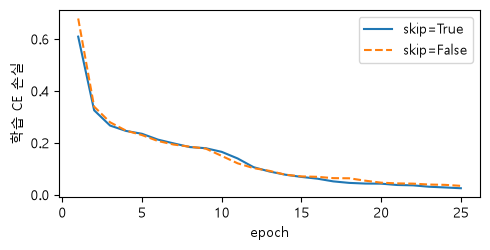

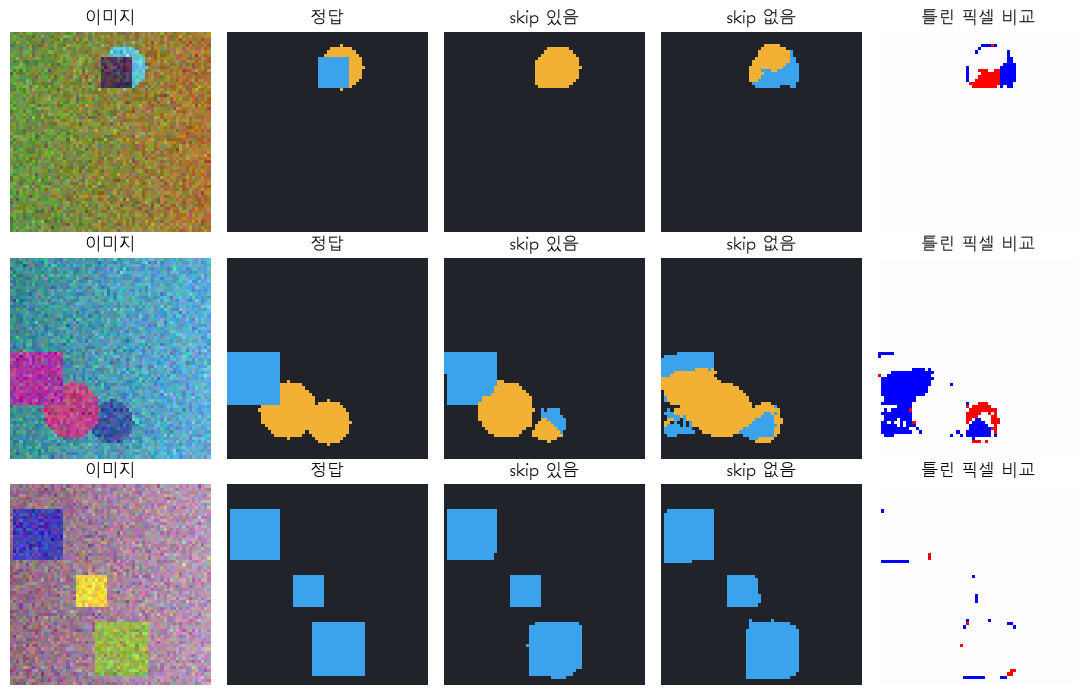

skip=True  3장 틀린 픽셀 수: 246
skip=False 3장 틀린 픽셀 수: 505


In [14]:
# [보강] 학습 곡선 · 검증 이미지 3장의 예측과 틀린 픽셀
fig, ax = plt.subplots(1, 1, figsize=(5, 2.6))
for skip, style in [(True, "-"), (False, "--")]:
    ax.plot(range(1, EPOCHS + 1), results[skip]["history"], style,
            label=f"skip={skip}")
ax.set_xlabel("epoch")
ax.set_ylabel("학습 CE 손실")
ax.legend()
plt.tight_layout()
plt.show()

show = [0, 1, 2]
fig, ax = plt.subplots(len(show), 5, figsize=(11, 7))
for r, i in enumerate(show):
    p_on, p_off = results[True]["pred"][i], results[False]["pred"][i]
    panels = [(X_val[i].permute(1, 2, 0), None, "이미지"),
              (Y_val[i], CMAP, "정답"),
              (p_on, CMAP, "skip 있음"),
              (p_off, CMAP, "skip 없음"),
              ((p_on != Y_val[i]).int() - (p_off != Y_val[i]).int(),
               "bwr", "틀린 픽셀 비교")]
    for c, (im, cmap, title) in enumerate(panels):
        if cmap is CMAP:
            ax[r, c].imshow(im, cmap=cmap, vmin=0, vmax=2)
        elif cmap == "bwr":
            ax[r, c].imshow(im, cmap=cmap, vmin=-1, vmax=1)
        else:
            ax[r, c].imshow(im)
        ax[r, c].set_title(title)
        ax[r, c].axis("off")
plt.tight_layout()
plt.show()


# 그림 마지막 열: 빨강 = skip 있음만 틀림 · 파랑 = skip 없음만 틀림
for skip in [True, False]:
    wrong = (results[skip]["pred"][show] != Y_val[show]).sum().item()
    print(f"skip={skip!s:5} 3장 틀린 픽셀 수: {wrong}")

**예측 정답** · **경계 정확도** 차이가 훨씬 큼 — 픽셀 정확도는 0.48%p 차이, 경계 정확도는 4.39%p 차이 (경계는 전체 픽셀의 6.5%뿐이라 픽셀 정확도에는 거의 안 드러남)

**결과 해설** · GPU(RTX 3060)에서 실행한 값이며 두 번 실행해 같은 값 확인. CPU에서는 연산 순서 차이로 소수 셋째 자리부터 달라지지만(CPU 실행: mIoU 0.9199 vs 0.8850 · 경계 정확도 0.8986 vs 0.8397) 결론은 같음

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>픽셀 정확도 0.9841 &#124; mIoU 0.9048 &#124; mDice 0.9490 &#124; 경계 정확도 0.8855</code></td>
<td style="text-align: left;">skip 있음 — 모든 지표가 더 높음</td>
</tr>
<tr>
<td style="text-align: left;"><code>클래스별 IoU: [0.9887, 0.8628, 0.863]</code></td>
<td style="text-align: left;">skip 있음 — 원 · 사각형 IoU 0.86</td>
</tr>
<tr>
<td style="text-align: left;"><code>픽셀 정확도 0.9793 &#124; mIoU 0.8799 &#124; mDice 0.9345 &#124; 경계 정확도 0.8416</code></td>
<td style="text-align: left;">skip 없음 — 픽셀 정확도는 비슷해도 경계가 크게 떨어짐</td>
</tr>
<tr>
<td style="text-align: left;"><code>클래스별 IoU: [0.985, 0.8277, 0.827]</code></td>
<td style="text-align: left;">skip 없음 — 배경 IoU는 거의 같고 원 · 사각형에서 0.035씩 낮음</td>
</tr>
<tr>
<td style="text-align: left;"><code>경계 픽셀 비율: 0.0652</code></td>
<td style="text-align: left;">경계는 6.5% → 경계를 많이 틀려도 픽셀 정확도는 조금만 내려감</td>
</tr>
<tr>
<td style="text-align: left;"><code>skip=True  3장 틀린 픽셀 수: 246</code></td>
<td style="text-align: left;">그림의 검증 3장 기준</td>
</tr>
<tr>
<td style="text-align: left;"><code>skip=False 3장 틀린 픽셀 수: 505</code></td>
<td style="text-align: left;">약 2배, 그림 마지막 열의 파랑(skip 없음만 틀림)이 빨강보다 넓음</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">지표</th>
<th style="text-align: left;">skip 있음</th>
<th style="text-align: left;">skip 없음</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">읽는 법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">픽셀 정확도</td>
<td style="text-align: left;">0.9841</td>
<td style="text-align: left;">0.9793</td>
<td style="text-align: left;">0.0048</td>
<td style="text-align: left;">배경 84%에 묻혀 차이가 작게 보임</td>
</tr>
<tr>
<td style="text-align: left;">mIoU</td>
<td style="text-align: left;">0.9048</td>
<td style="text-align: left;">0.8799</td>
<td style="text-align: left;">0.0249</td>
<td style="text-align: left;">작은 클래스(원 · 사각형)의 차이가 드러남</td>
</tr>
<tr>
<td style="text-align: left;">mDice</td>
<td style="text-align: left;">0.9490</td>
<td style="text-align: left;">0.9345</td>
<td style="text-align: left;">0.0145</td>
<td style="text-align: left;">IoU와 같은 순위, 값은 더 큼</td>
</tr>
<tr>
<td style="text-align: left;">경계 정확도</td>
<td style="text-align: left;">0.8855</td>
<td style="text-align: left;">0.8416</td>
<td style="text-align: left;">0.0439</td>
<td style="text-align: left;">skip 연결이 되살리는 것 = <strong>경계</strong></td>
</tr>
</tbody>
</table>

**그림 읽는 법** · 마지막 열은 (skip 있음이 틀림) - (skip 없음이 틀림) → **빨강** = skip 있음만 틀린 픽셀, **파랑** = skip 없음만 틀린 픽셀, 흰색 = 둘 다 맞음 또는 둘 다 틀림. skip 없음은 바닥(16×16)에서 키운 정보만 있어 **3번째 줄**은 사각형 모서리가 둥글어지고 테두리가 1 ~ 2픽셀씩 번지며, **2번째 줄**은 붙어 있는 도형 사이 경계를 못 잡아 원 · 사각형을 한 덩어리로 섞음

**학습 곡선** · 두 모델의 학습 손실은 거의 겹침(마지막 epoch 0.0246 vs 0.0338, 위 출력) → 평균 손실도 픽셀 정확도처럼 경계 차이를 잘 드러내지 못함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">U-Net (skip 있음)</td>
<td style="text-align: left;">인코더의 64×64 · 32×32 특징을 디코더에 이어 붙임 → 경계 선명</td>
<td style="text-align: left;">분할의 기본 선택, 경계 · 작은 물체가 중요할 때</td>
</tr>
<tr>
<td style="text-align: left;">인코더-디코더 (skip 없음)</td>
<td style="text-align: left;">바닥 16×16 정보만으로 복원 → 경계가 뭉개짐, 파라미터 조금 적음</td>
<td style="text-align: left;">출력이 입력 복원인 오토인코더 (skip이 있으면 그대로 베낌)</td>
</tr>
<tr>
<td style="text-align: left;">픽셀 정확도로 비교</td>
<td style="text-align: left;">두 모델 차이 0.0048 → "비슷하다"로 오판</td>
<td style="text-align: left;">학습이 되는지 확인할 때만</td>
</tr>
<tr>
<td style="text-align: left;">mIoU · 경계 정확도로 비교</td>
<td style="text-align: left;">차이 0.0249 · 0.0439 → 구조 차이가 보임</td>
<td style="text-align: left;">모델 · 구조 비교 보고 (기본 선택)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 비교 실험에서 seed · 데이터 순서 · epoch 중 하나라도 다르면 차이가 skip 때문인지 운 때문인지 구분 불가 → `train_model()`처럼 조건을 함수 하나로 묶기

> ✅ **한 줄 정리** · skip 연결은 인코더의 고해상도 특징을 디코더에 건네 경계를 되살리며, 그 효과는 픽셀 정확도가 아니라 mIoU와 경계 정확도에서 드러난다.

**딥러닝 코드에서는** · 실제 사진 분할(세그멘테이션-2)에서도 같은 순서: 정수 마스크 Dataset → U-Net 또는 사전학습 모델 → 픽셀 CE (+ Dice) → 검증 혼동 행렬로 mIoU · Dice → 예측 마스크 그림

---
## 6. 백지 복습

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 6-1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">분류 · 탐지 · 의미 분할 · 인스턴스 분할은 각각 무엇까지 답하는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">분할 출력의 모양은 무엇이고, 예측 마스크는 어느 축에서 고르는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">CrossEntropy에 넣는 정답 마스크의 모양 · 자료형은?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">분할의 CE는 어떻게 계산되며 <code>ignore_index</code>는 무엇을 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">마스크 크기를 바꿀 때 bilinear를 쓰면 안 되는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">FCN은 분류 CNN의 무엇을 바꿔 픽셀마다 예측하는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">64×64 입력이 풀링 2번 U-Net의 바닥에서 어떤 크기가 되는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">U-Net의 skip은 무엇을 어느 축으로 합치는가?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">픽셀 정확도 대신 mIoU를 보는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">CE와 Dice 손실은 작은 클래스를 어떻게 다르게 다루는가?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">skip 연결의 효과는 어느 지표에서 드러났는가?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 6-2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 분할 출력 `torch.randn(2, 3, 8, 8)`에서 예측 마스크를 만들고 **모양**을 출력
2. 마스크 `torch.tensor([[0, 1], [2, 1]])`를 one-hot으로 바꿔 `(C, H, W)` **모양**을 출력
3. `pred = torch.tensor([1, 1, 0, 0])` · `target = torch.tensor([1, 0, 1, 0])`에서 클래스 1의 **IoU**와 **Dice**를 소수 넷째 자리로 출력
4. `nn.ConvTranspose2d(8, 4, 2, stride=2)`에 `(1, 8, 16, 16)`을 넣은 출력 **모양**을 출력

In [15]:
# 6-2 직접 작성

### 6-3. 모범 답안 · 6-1 · 6-2를 다 쓴 뒤에 보기

#### 6-1 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">분류 = 무엇이 있나, 탐지 = 어디에 몇 개(상자), 의미 분할 = 픽셀마다 클래스, 인스턴스 분할 = 개체마다 마스크</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;"><code>(N, C, H, W)</code>, 클래스 축 <code>dim=1</code>에서 <code>argmax</code> → <code>(N, H, W)</code></td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;"><code>(N, H, W)</code> long 정수 마스크 (채널 축 없음, 정규화 금지)</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">픽셀마다 -log(정답 확률) → 평균, <code>ignore_index</code> 픽셀은 평균에서 제외</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">1과 2 사이 값처럼 없는 클래스 번호가 생김 → 마스크는 nearest</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">완전 연결층을 같은 가중치의 1×1 · 7×7 합성곱으로 바꿈 → 위치 유지 · 입력 크기 자유</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">64 → 32 → 16, 채널 64 → <code>(1, 64, 16, 16)</code></td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">인코더 고해상도 특징을 디코더에 <code>torch.cat(dim=1)</code>로 이어 붙임</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">배경이 많으면 작은 클래스를 놓쳐도 픽셀 정확도가 높음, mIoU는 클래스마다 같은 비중</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">CE는 픽셀마다 같은 비중(작은 클래스 손실 작음), Dice는 클래스마다 같은 비중(작은 클래스 놓치면 큼)</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">픽셀 정확도 차이 0.0048, mIoU 0.0249 · 경계 정확도 0.0439 → 경계에서 드러남</td>
</tr>
</tbody>
</table>

#### 6-2 답

```python
# 1. 클래스 축(dim=1)에서 argmax → 예측 마스크
print(tuple(torch.randn(2, 3, 8, 8).argmax(dim=1).shape))  # (2, 8, 8)

# 2. one-hot (H, W, C) → permute → (C, H, W)
m = torch.tensor([[0, 1], [2, 1]])
print(tuple(F.one_hot(m, 3).permute(2, 0, 1).shape))  # (3, 2, 2)

# 3. 클래스 1의 IoU · Dice
pred = torch.tensor([1, 1, 0, 0])
target = torch.tensor([1, 0, 1, 0])
p, t = pred == 1, target == 1
inter = (p & t).sum().item()
print(round(inter / (p | t).sum().item(), 4))  # 0.3333
print(round(2 * inter / (p.sum() + t.sum()).item(), 4))  # 0.5

# 4. 전치 합성곱 k = s = 2 → 크기 2배
up = nn.ConvTranspose2d(8, 4, 2, stride=2)
print(tuple(up(torch.randn(1, 8, 16, 16)).shape))  # (1, 4, 32, 32)
```

---
## 7. 면접 30초 답변

**Q1. Semantic Segmentation과 Instance Segmentation의 차이는 무엇인가요?**
> Semantic Segmentation은 모든 픽셀에 클래스를 붙이지만 같은 클래스의 개체끼리는 구분하지 않습니다. 그래서 붙어 있는 물체 두 개가 한 영역이 되어 개수를 셀 수 없습니다. Instance Segmentation은 개체마다 마스크를 따로 내서 같은 클래스도 하나하나 구분합니다. 영역 · 넓이가 필요하면 의미 분할, 개체별 모양과 개수가 필요하면 인스턴스 분할을 씁니다.

**Q2. 분할 모델을 픽셀 정확도로 평가하면 어떤 문제가 있나요?**
> 배경이 대부분인 이미지에서는 작은 물체를 통째로 놓쳐도 픽셀 정확도가 높게 나옵니다. 제 실습 데이터도 배경이 84%라, 4×4 예제에서 사각형을 놓친 예측이 픽셀 정확도 87.5%였지만 mIoU는 0.53이었습니다. 그래서 클래스마다 IoU를 구해 평균한 mIoU나 Dice로 비교합니다.

**Q3. U-Net의 skip 연결은 왜 필요한가요?**
> 인코더에서 풀링을 거치면 무엇인지는 알지만 정확한 위치 정보가 흐려지고, 업샘플링만으로는 그 세부가 돌아오지 않습니다. skip 연결은 인코더의 고해상도 특징을 디코더에 채널 축으로 이어 붙여 경계를 되살립니다. 같은 조건으로 학습해 보니 픽셀 정확도 차이는 0.5%p였지만 경계 정확도는 0.886 대 0.842로 skip이 있는 쪽이 4.4%p 높았습니다.

**Q4. CrossEntropy 대신 Dice 손실을 쓰는 경우는 언제인가요?**
> CrossEntropy는 픽셀마다 같은 비중이라 작은 클래스를 놓쳐도 손실이 작습니다. Dice 손실은 클래스마다 겹침 비율을 보기 때문에 작은 클래스를 통째로 놓치면 크게 벌합니다. 그래서 병변처럼 작은 물체가 중요한 문제에서 CE와 Dice를 더해 쓰는 경우가 많습니다.

---
## 8. 전체 코드

0 ~ 5장 코드를 한 셀에 모음. **이 셀만 실행해도 전체가 동작**하며(데이터 생성 · 두 모델 학습 포함), 그림은 각 섹션에서 보고 여기서는 닫음(`plt.close`). 섹션 구분은 `# ===== [번호]` 주석.

In [16]:
# ===== [0-1]
# [보강] 라이브러리 · 재현성 · 장치 설정
import os
import random
import time

if "KMP_DUPLICATE_LIB_OK" not in os.environ:  # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # numpy · torch OpenMP 중복

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from scipy import ndimage  # ndimage.label → 붙어 있는 덩어리 번호
from torch import nn

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # GPU 연산도 같은 결과
    torch.backends.cudnn.benchmark = False  # 매번 같은 알고리즘 선택


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)


# 그림 한글 글꼴 (있을 때만) · 마스크 색 (배경 · 원 · 사각형)
fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
CMAP = ListedColormap(["#20232a", "#f2b134", "#3ba3ec"])  # 0 · 1 · 2
CLASSES = ["배경", "원", "사각형"]


# ===== [0-2]
# [보강] 도형 그리기: 이미지 · 의미 마스크 · 인스턴스 마스크를 함께 칠함
H = W = 64
YY, XX = np.mgrid[0:H, 0:W]  # 픽셀마다 (행, 열) 좌표


def paint(img, sem, inst, cls, cy, cx, size, color, k, rng):
    if cls == 1:  # 원: 중심에서 거리 ≤ 반지름
        region = (YY - cy) ** 2 + (XX - cx) ** 2 <= size ** 2
    else:  # 사각형: 왼쪽 위 (cy, cx) · 한 변 size
        region = ((YY >= cy) & (YY < cy + size)
                  & (XX >= cx) & (XX < cx + size))
    noise = rng.normal(0, 0.08, (3, region.sum()))
    img[:, region] = np.asarray(color)[:, None] + noise  # 색 + 잡음
    sem[region] = cls  # 의미 마스크: 클래스 번호
    inst[region] = k  # 인스턴스 마스크: 개체 번호


def make_sample(rng):
    base = rng.uniform(0.2, 0.6, 3)[:, None, None]  # 배경 밝기
    tilt = rng.uniform(-0.3, 0.3, 3)[:, None, None]  # 좌우 그러데이션
    img = base + tilt * (XX / W) + rng.normal(0, 0.08, (3, H, W))
    sem = np.zeros((H, W), np.int64)
    inst = np.zeros((H, W), np.int64)
    for k in range(1, rng.integers(2, 5) + 1):  # 도형 2 ~ 4개
        cls = rng.integers(1, 3)  # 1 원 · 2 사각형
        color = rng.uniform(0, 1, 3)  # 색은 클래스와 무관
        if cls == 1:
            r = rng.integers(5, 13)
            cy, cx = rng.integers(r, H - r), rng.integers(r, W - r)
            paint(img, sem, inst, 1, cy, cx, r, color, k, rng)
        else:
            s = rng.integers(8, 22)
            cy, cx = rng.integers(0, H - s), rng.integers(0, W - s)
            paint(img, sem, inst, 2, cy, cx, s, color, k, rng)
    return np.clip(img, 0, 1).astype(np.float32), sem, inst


def make_dataset(n, seed):
    rng = np.random.default_rng(seed)
    imgs, masks = zip(*[make_sample(rng)[:2] for _ in range(n)])
    return torch.tensor(np.stack(imgs)), torch.tensor(np.stack(masks))


# 학습 600장 · 검증 100장 (seed가 달라 겹치지 않음)
X_train, Y_train = make_dataset(600, seed=0)
X_val, Y_val = make_dataset(100, seed=1)
print("X_train:", tuple(X_train.shape), X_train.dtype)
print("Y_train:", tuple(Y_train.shape), Y_train.dtype)
print("X_val:", tuple(X_val.shape), "| Y_val:", tuple(Y_val.shape))
ratio = torch.bincount(Y_train.flatten(), minlength=3) / Y_train.numel()
print("클래스 비율:", {c: round(r, 3) for c, r in
                  zip(CLASSES, ratio.tolist())})


# 앞 4장: 이미지 위 · 마스크 아래
fig, ax = plt.subplots(2, 4, figsize=(8, 4))
for i in range(4):
    ax[0, i].imshow(X_train[i].permute(1, 2, 0))  # CHW → HWC
    ax[1, i].imshow(Y_train[i], cmap=CMAP, vmin=0, vmax=2)
    ax[0, i].set_title(f"이미지 {i}")
    ax[1, i].set_title(f"마스크 {i}")
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
plt.close()


# ===== [1-1]
# [보강] 같은 장면 1장: 원 2개를 붙여 그리고 사각형 1개
rng = np.random.default_rng(7)
img = np.full((3, H, W), 0.3) + rng.normal(0, 0.05, (3, H, W))
sem = np.zeros((H, W), np.int64)
inst = np.zeros((H, W), np.int64)
paint(img, sem, inst, 1, 20, 18, 9, (0.9, 0.6, 0.2), 1, rng)  # 원 A
paint(img, sem, inst, 1, 20, 35, 9, (0.9, 0.6, 0.2), 2, rng)  # 원 B
paint(img, sem, inst, 2, 38, 30, 18, (0.2, 0.6, 0.9), 3, rng)


# ① 분류 (다중 라벨): 어떤 클래스가 있나 → 값 2개
present = [int((sem == c).any()) for c in (1, 2)]
print("① 분류      출력:", present, "→ 값", len(present), "개")


# ② 탐지: 개체마다 상자 (x1, y1, x2, y2) + 클래스
boxes = []
for k in range(1, inst.max() + 1):
    ys, xs = np.where(inst == k)  # 개체 k의 픽셀 좌표
    cls = int(sem[ys[0], xs[0]])
    boxes.append((int(xs.min()), int(ys.min()),
                  int(xs.max()), int(ys.max()), cls))
print("② 탐지      출력:", boxes, "→ 값", len(boxes) * 5, "개")


# ③ 의미 분할: 픽셀마다 클래스 → 원이 몇 덩어리로 보이나
_, n_blob = ndimage.label(sem == 1)  # 상하좌우로 이어진 덩어리 수
print("③ 의미 분할 출력:", sem.shape, "→ 값", sem.size, "개",
      "| 원 덩어리 수:", n_blob)


# ④ 인스턴스 분할: 개체마다 마스크 1장
inst_masks = np.stack([inst == k for k in range(1, inst.max() + 1)])
print("④ 인스턴스  출력:", inst_masks.shape, "→ 원 개수:",
      sum(b[-1] == 1 for b in boxes))


# 네 가지 출력을 한 그림으로
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
ax[0].imshow(np.clip(img, 0, 1).transpose(1, 2, 0))
ax[0].set_title(f"① 분류 {present}")
ax[1].imshow(np.clip(img, 0, 1).transpose(1, 2, 0))
for x1, y1, x2, y2, c in boxes:
    ax[1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                  fill=False, color="red"))
ax[1].set_title("② 탐지 (상자 3개)")
ax[2].imshow(sem, cmap=CMAP, vmin=0, vmax=2)
ax[2].set_title("③ 의미 분할 (원 1덩어리)")
inst_cmap = ListedColormap(["#20232a", "#ff7f0e", "#2ca02c", "#d62728"])
ax[3].imshow(inst, cmap=inst_cmap, vmin=0, vmax=3)  # 개체마다 다른 색
ax[3].set_title("④ 인스턴스 (개체 3개)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.close()


# ===== [1-2]
# [보강] 같은 이미지 4장을 분류 · 분할 모델에 넣기
x = X_train[:4]  # 이미지 4장 (N, 3, 64, 64)


# 분류 모델: 합성곱 → 평탄화 → Linear → (N, C)
classifier = nn.Sequential(
    nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),  # (N, 8, 64, 64) → (N, 8, 1, 1)
    nn.Flatten(),  # → (N, 8)
    nn.Linear(8, 3))  # → (N, 3)


# 분할 모델: 합성곱만 → (N, C, H, W)
segmenter = nn.Sequential(
    nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),
    nn.Conv2d(8, 3, 1))  # 1×1 합성곱: 픽셀마다 점수 3개


cls_out, seg_out = classifier(x), segmenter(x)
print("분류 출력:", tuple(cls_out.shape),
      "| 분할 출력:", tuple(seg_out.shape))


# 클래스 축(dim=1)에서 가장 큰 번호 → 예측
print("분류 예측:", tuple(cls_out.argmax(dim=1).shape),
      "| 분할 예측:", tuple(seg_out.argmax(dim=1).shape))


# 흔한 실수: dim을 빼먹거나 0으로
print("argmax() :", tuple(seg_out.argmax().shape), "← 전체에서 1개")
print("argmax(0):", tuple(seg_out.argmax(dim=0).shape), "← 배치 축")


# 픽셀 하나의 확률 합 = 1 (softmax도 dim=1)
prob = seg_out.softmax(dim=1)
print("픽셀 (0, 10, 10) 확률 합:", round(prob[0, :, 10, 10].sum().item(), 4))


# ===== [1-3]
# [보강] 무작위 점수(모델 출력 흉내)와 정답 마스크 4장
logits = torch.randn(4, 3, 64, 64)  # 모델 출력 (N, C, H, W)
target = Y_train[:4]  # 정답 마스크
print("정답 마스크:", tuple(target.shape), target.dtype,
      "| 값 종류:", target.unique().tolist())


# 방식 1: 정수 마스크 (N, H, W) long → CrossEntropy 기본 입력
loss_long = F.cross_entropy(logits, target)
print("long 마스크 loss  :", round(loss_long.item(), 4))


# 방식 2: one-hot (N, C, H, W) float → 클래스 확률로 받음
onehot = F.one_hot(target, num_classes=3)  # (N, H, W, C)
onehot = onehot.permute(0, 3, 1, 2).float()  # → (N, C, H, W)
loss_onehot = F.cross_entropy(logits, onehot)
print("one-hot", tuple(onehot.shape), "loss:", round(loss_onehot.item(), 4))


# 흔한 실수 1: 마스크에 채널 축 (N, 1, H, W)
try:
    F.cross_entropy(logits, target.unsqueeze(1))
except RuntimeError as e:
    print("(N, 1, H, W) →", type(e).__name__, "→ squeeze(1)로 해결")


# 흔한 실수 2: 정수 마스크를 float로
try:
    F.cross_entropy(logits, target.float())
except RuntimeError as e:
    print("float (N, H, W) →", type(e).__name__, "→ .long()으로 해결")


# ===== [2-1]
# [보강] 2×2 이미지 1장 · 클래스 3개 · 점수(logit)를 직접 지정
logits = torch.tensor([[[[2.0, 0.0], [0.0, 1.0]],  # 클래스 0 점수
                        [[0.0, 2.0], [0.0, 0.0]],  # 클래스 1 점수
                        [[0.0, 0.0], [2.0, 0.0]]]])  # 클래스 2 점수
target = torch.tensor([[[0, 1], [2, 2]]])  # (1, 2, 2) 정답
print("logits", tuple(logits.shape), "| target", tuple(target.shape))


# 손으로: 픽셀마다 -log(정답 클래스 확률) → 평균
prob = logits.softmax(dim=1)
p_true = prob.gather(1, target.unsqueeze(1)).squeeze(1)  # 정답 확률
manual = -p_true.log()
print("정답 확률:", [round(v, 4) for v in p_true.flatten().tolist()])
print("픽셀 손실:", [round(v, 4) for v in manual.flatten().tolist()])
print("직접 평균:", round(manual.mean().item(), 4))


# PyTorch: 같은 값 · reduction="none"이면 픽셀별 지도
print("CE 평균  :", round(F.cross_entropy(logits, target).item(), 4))
loss_map = F.cross_entropy(logits, target, reduction="none")
print("손실 지도 :", tuple(loss_map.shape))


# ignore_index: 255로 표시한 픽셀은 계산에서 제외
target_ign = target.clone()
target_ign[0, 1, 1] = 255  # 마지막 픽셀 = 경계 · 모름
ce_ign = F.cross_entropy(logits, target_ign, ignore_index=255)
print("255 제외 평균:", round(ce_ign.item(), 4),
      "| 앞 3픽셀 평균:", round(manual.flatten()[:3].mean().item(), 4))


# ===== [2-2]
# [보강] 2×2 특징 지도를 4×4로 키우기
small = torch.tensor([[[[1.0, 2.0], [3.0, 4.0]]]])  # (1, 1, 2, 2)
near = F.interpolate(small, scale_factor=2, mode="nearest")
bili = F.interpolate(small, scale_factor=2, mode="bilinear",
                     align_corners=False)
print("nearest 1행 :", near[0, 0, 0].tolist())  # 값 복사
print("bilinear 1행:", bili[0, 0, 0].tolist())  # 이웃 가중 평균


# 학습 파라미터 수: 보간 0 · 전치 합성곱 · 보간 + 합성곱
up_t = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
up_c = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                     nn.Conv2d(16, 8, kernel_size=3, padding=1))
n_param = {name: sum(p.numel() for p in m.parameters())
           for name, m in [("ConvT", up_t), ("Up+Conv", up_c)]}
feat = torch.randn(1, 16, 8, 8)
print("출력:", tuple(up_t(feat).shape), tuple(up_c(feat).shape),
      "| 파라미터:", n_param)


# 겹침 횟수: 입력 · 가중치를 모두 1로 → 출력 = 찍힌 횟수
def overlap(k, s, p=0):
    up = nn.ConvTranspose2d(1, 1, k, stride=s, padding=p, bias=False)
    nn.init.ones_(up.weight)
    with torch.no_grad():
        out = up(torch.ones(1, 1, 4, 4))
    return out.shape[-1], out[0, 0, 3, 2:6].int().tolist()  # 안쪽 4칸


print("k=3, s=2 → 크기 %d | 안쪽 겹침 %s" % overlap(3, 2))  # 고르지 않음
print("k=4, s=2 → 크기 %d | 안쪽 겹침 %s" % overlap(4, 2, 1))  # 고름
print("k=2, s=2 → 크기 %d | 안쪽 겹침 %s" % overlap(2, 2))  # 겹침 없음


# ===== [2-3]
# [보강] 1. Linear를 픽셀마다 적용 = 1×1 합성곱 (가중치를 옮겨 확인)
fc = nn.Linear(16, 3)  # 특징 16개 → 클래스 점수 3개
conv1 = nn.Conv2d(16, 3, kernel_size=1)
with torch.no_grad():
    conv1.weight.copy_(fc.weight.view(3, 16, 1, 1))
    conv1.bias.copy_(fc.bias)
feat = torch.randn(2, 16, 8, 8)
by_fc = fc(feat.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)  # 픽셀마다 Linear
print("Linear 픽셀별 = 1×1 Conv:",
      torch.allclose(by_fc, conv1(feat), atol=1e-6))


# 2. 작은 FCN: 합성곱으로 1/4까지 줄임 → 1×1 점수 → 4배 키움
class TinyFCN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.ReLU(),  # 1/2
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU())  # 1/4
        self.score = nn.Conv2d(32, num_classes, 1)  # 픽셀별 점수

    def forward(self, x):
        s = self.score(self.features(x))  # (N, C, H/4, W/4)
        return F.interpolate(s, size=x.shape[-2:], mode="bilinear",
                             align_corners=False)  # 입력 크기로


fcn = TinyFCN()
for size in [64, 96]:  # 입력 크기가 달라도 그대로 동작
    print(f"FCN 입력 {size}×{size} → 출력",
          tuple(fcn(torch.randn(1, 3, size, size)).shape))


# 3. 분류 모델(Flatten + Linear)은 입력 크기가 고정
clf = nn.Sequential(nn.Conv2d(3, 4, 3, stride=4, padding=1),  # 1/4
                    nn.Flatten(), nn.Linear(4 * 16 * 16, 3))  # 64 기준
print("분류 64×64 →", tuple(clf(torch.randn(1, 3, 64, 64)).shape))
try:
    clf(torch.randn(1, 3, 96, 96))
except RuntimeError as e:
    print("분류 96×96 →", type(e).__name__, "(Linear 입력 길이 불일치)")


# ===== [3-1]
# [보강] 블록: 3×3 합성곱 2번 (padding=1 → 크기 유지)
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True))


# [보강] U-Net: 인코더 2단 → 바닥 → 디코더 2단 → 1×1 점수
class UNet(nn.Module):
    def __init__(self, num_classes=3, base=16, skip=True):
        super().__init__()
        self.skip = skip
        c1, c2, c3 = base, base * 2, base * 4  # 16 · 32 · 64
        m = 2 if skip else 1  # skip이면 이어 붙여 채널 2배
        self.enc1, self.enc2 = block(3, c1), block(c1, c2)
        self.pool = nn.MaxPool2d(2)  # 크기 1/2
        self.bottom = block(c2, c3)
        self.up2 = nn.ConvTranspose2d(c3, c2, 2, stride=2)  # 크기 2배
        self.dec2 = block(c2 * m, c2)
        self.up1 = nn.ConvTranspose2d(c2, c1, 2, stride=2)
        self.dec1 = block(c1 * m, c1)
        self.head = nn.Conv2d(c1, num_classes, 1)

    def forward(self, x, trace=None):
        e1 = self.enc1(x)  # 64×64 고해상도 특징
        e2 = self.enc2(self.pool(e1))  # 32×32
        b = self.bottom(self.pool(e2))  # 16×16 바닥
        u2 = self.up2(b)  # 16 → 32
        c2 = torch.cat([u2, e2], dim=1) if self.skip else u2  # 채널 축
        d2 = self.dec2(c2)
        u1 = self.up1(d2)  # 32 → 64
        c1 = torch.cat([u1, e1], dim=1) if self.skip else u1
        d1 = self.dec1(c1)
        out = self.head(d1)  # 픽셀마다 클래스 점수
        if trace is not None:  # 단계별 모양 기록
            names = ["enc1", "enc2", "bottom", "up2", "cat2", "dec2",
                     "up1", "cat1", "dec1", "out"]
            trace += zip(names, [e1, e2, b, u2, c2, d2, u1, c1, d1, out])
        return out


# 모양 추적: 손계산 표와 비교
unet = UNet()
trace = []
unet(torch.randn(1, 3, 64, 64), trace)
expected = {"enc1": (1, 16, 64, 64), "enc2": (1, 32, 32, 32),
            "bottom": (1, 64, 16, 16), "up2": (1, 32, 32, 32),
            "cat2": (1, 64, 32, 32), "dec2": (1, 32, 32, 32),
            "up1": (1, 16, 64, 64), "cat1": (1, 32, 64, 64),
            "dec1": (1, 16, 64, 64), "out": (1, 3, 64, 64)}  # 손계산 표
for name, t in trace:
    ok = tuple(t.shape) == expected[name]
    print(f"{name:>6}: {tuple(t.shape)} 손계산 일치 {ok}")
print("파라미터 수:", sum(p.numel() for p in unet.parameters()))


# ===== [3-2]
# [보강] 같은 크기의 인코더 · 디코더 특징 2개
e1 = torch.randn(1, 16, 64, 64)  # 인코더 특징 (세밀한 위치)
d1 = torch.randn(1, 16, 64, 64)  # 디코더 특징 (넓은 문맥)


# U-Net: 이어 붙이기 · FCN: 더하기
print("cat dim=1:", tuple(torch.cat([d1, e1], dim=1).shape))
print("더하기    :", tuple((d1 + e1).shape))


# 흔한 실수: dim을 빼면 배치 축(0)으로 붙음 → 에러 없이 이미지 2장
print("cat dim 생략:", tuple(torch.cat([d1, e1]).shape))


# 크기가 4의 배수가 아니면 이어 붙일 때 에러 (풀링 2번)
try:
    unet(torch.randn(1, 3, 63, 63))
except RuntimeError as e:
    print("입력 63×63 →", type(e).__name__, "(크기 불일치)")


# skip 있음 · 없음 비교: 디코더 입력 채널 · 파라미터 수
for skip in [True, False]:
    m = UNet(skip=skip)
    n = sum(p.numel() for p in m.parameters())
    print(f"skip={skip!s:5} dec1 입력 {m.dec1[0].in_channels}채널"
          f" | 파라미터 {n:,}")


# ===== [4-1]
# [보강] 혼동 행렬로 픽셀 정확도 · 클래스별 IoU · Dice
def seg_metrics(pred, target, num_classes=3):
    idx = target.flatten() * num_classes + pred.flatten()
    cm = torch.bincount(idx, minlength=num_classes ** 2)
    cm = cm.reshape(num_classes, num_classes).double()  # 행 정답 · 열 예측
    inter = cm.diag()  # 정답 = 예측 = c
    area_t, area_p = cm.sum(1), cm.sum(0)  # 정답 넓이 · 예측 넓이
    iou = inter / (area_t + area_p - inter)  # 교집합 / 합집합
    dice = 2 * inter / (area_t + area_p)  # 2 × 교집합 / 넓이 합
    acc = inter.sum() / cm.sum()
    return acc.item(), iou, dice  # 둘 다 없는 클래스는 nan


# 손계산과 같은 4×4 예제
target = torch.tensor([[0, 0, 0, 0], [0, 1, 1, 0],
                       [0, 1, 0, 0], [0, 0, 0, 2]])
pred = torch.tensor([[0, 0, 0, 0], [0, 1, 1, 0],
                     [0, 1, 1, 0], [0, 0, 0, 0]])
acc, iou, dice = seg_metrics(pred, target)
print("픽셀 정확도:", acc)
print("IoU :", iou.round(decimals=4).tolist(),
      "→ mIoU", round(iou.mean().item(), 4))
print("Dice:", dice.round(decimals=4).tolist(),
      "→ mDice", round(dice.mean().item(), 4))


# 손계산(분수)과 일치 확인
assert acc == 14 / 16
assert torch.allclose(iou, torch.tensor([11 / 13, 3 / 4, 0],
                                        dtype=torch.double))
assert torch.allclose(dice, torch.tensor([22 / 24, 6 / 7, 0],
                                         dtype=torch.double))
print("손계산 일치: True")


# Dice = 2·IoU / (1 + IoU) 관계
print("2·IoU/(1+IoU):", (2 * iou / (1 + iou)).round(decimals=4).tolist())


# ===== [4-2]
# [보강] Dice 손실: 1 - (클래스별 soft Dice의 평균)
def dice_loss(logits, target, eps=1e-6):
    prob = logits.softmax(dim=1)  # (N, C, H, W)
    onehot = F.one_hot(target, logits.shape[1]).permute(0, 3, 1, 2)
    inter = (prob * onehot).sum(dim=(0, 2, 3))  # 클래스별 겹침
    total = prob.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
    return 1 - ((2 * inter + eps) / (total + eps)).mean()


# 4×4 정답(4-1)에서 딱 1픽셀만 틀린 예측 두 가지
def confident(mask, scale=5.0):  # 정답 위치에 높은 점수
    return F.one_hot(mask, 3).permute(2, 0, 1)[None].float() * scale


t = target[None]  # (1, 4, 4)
miss_small = target.clone()
miss_small[3, 3] = 0  # A: 사각형(1픽셀뿐) → 배경으로 틀림
miss_bg = target.clone()
miss_bg[0, 0] = 1  # B: 배경 1픽셀 → 원으로 틀림
for name, m in [("A 사각형 놓침", miss_small), ("B 배경 1칸 틀림", miss_bg)]:
    lg = confident(m)
    ce = F.cross_entropy(lg, t).item()
    dl = dice_loss(lg, t).item()
    print(f"{name}: CE {ce:.4f} | Dice 손실 {dl:.4f}"
          f" | CE + Dice {ce + dl:.4f}")


# ===== [5-1]
# [보강] 학습 함수: 같은 seed · 데이터 · 순서 · epoch로 학습
EPOCHS, BATCH, LR = 25, 16, 3e-3


def train_model(skip):
    set_seed()  # 가중치 초기값 · 섞는 순서까지 고정
    model = UNet(skip=skip).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_train, Y_train),
        batch_size=BATCH, shuffle=True,
        generator=torch.Generator().manual_seed(SEED))
    history, start = [], time.time()
    for epoch in range(EPOCHS):
        model.train()
        total = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)  # 픽셀별 CE 평균
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(x)
        history.append(total / len(X_train))
    return model, history, time.time() - start


# 경계 픽셀: 상하좌우 이웃과 클래스가 다른 픽셀
def boundary(mask):
    b = torch.zeros_like(mask, dtype=torch.bool)
    dv = mask[..., 1:, :] != mask[..., :-1, :]  # 위아래 다름
    dh = mask[..., :, 1:] != mask[..., :, :-1]  # 좌우 다름
    b[..., 1:, :] |= dv
    b[..., :-1, :] |= dv
    b[..., :, 1:] |= dh
    b[..., :, :-1] |= dh
    return b


results = {}
for skip in [True, False]:
    model, history, sec = train_model(skip)
    model.eval()
    with torch.no_grad():
        pred = model(X_val.to(device)).argmax(dim=1).cpu()
    acc, iou, dice = seg_metrics(pred, Y_val)  # 4-1 함수 재사용
    edge = boundary(Y_val)
    edge_acc = (pred[edge] == Y_val[edge]).float().mean().item()
    results[skip] = dict(pred=pred, history=history)
    print(f"skip={skip!s:5} | loss {history[0]:.4f} → {history[-1]:.4f}"
          f" | {sec:.1f}초")
    print(f"  픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"
          f" | mDice {dice.mean():.4f} | 경계 정확도 {edge_acc:.4f}")
    print("  클래스별 IoU:", iou.round(decimals=4).tolist())
print("경계 픽셀 비율:", round(edge.float().mean().item(), 4))


# ===== [5-2]
# [보강] 학습 곡선 · 검증 이미지 3장의 예측과 틀린 픽셀
fig, ax = plt.subplots(1, 1, figsize=(5, 2.6))
for skip, style in [(True, "-"), (False, "--")]:
    ax.plot(range(1, EPOCHS + 1), results[skip]["history"], style,
            label=f"skip={skip}")
ax.set_xlabel("epoch")
ax.set_ylabel("학습 CE 손실")
ax.legend()
plt.tight_layout()
plt.close()

show = [0, 1, 2]
fig, ax = plt.subplots(len(show), 5, figsize=(11, 7))
for r, i in enumerate(show):
    p_on, p_off = results[True]["pred"][i], results[False]["pred"][i]
    panels = [(X_val[i].permute(1, 2, 0), None, "이미지"),
              (Y_val[i], CMAP, "정답"),
              (p_on, CMAP, "skip 있음"),
              (p_off, CMAP, "skip 없음"),
              ((p_on != Y_val[i]).int() - (p_off != Y_val[i]).int(),
               "bwr", "틀린 픽셀 비교")]
    for c, (im, cmap, title) in enumerate(panels):
        if cmap is CMAP:
            ax[r, c].imshow(im, cmap=cmap, vmin=0, vmax=2)
        elif cmap == "bwr":
            ax[r, c].imshow(im, cmap=cmap, vmin=-1, vmax=1)
        else:
            ax[r, c].imshow(im)
        ax[r, c].set_title(title)
        ax[r, c].axis("off")
plt.tight_layout()
plt.close()


# 그림 마지막 열: 빨강 = skip 있음만 틀림 · 파랑 = skip 없음만 틀림
for skip in [True, False]:
    wrong = (results[skip]["pred"][show] != Y_val[show]).sum().item()
    print(f"skip={skip!s:5} 3장 틀린 픽셀 수: {wrong}")

torch 2.11.0+cu128 | device: cuda


X_train: (600, 3, 64, 64) torch.float32
Y_train: (600, 64, 64) torch.int64
X_val: (100, 3, 64, 64) | Y_val: (100, 64, 64)
클래스 비율: {'배경': 0.843, '원': 0.083, '사각형': 0.073}
① 분류      출력: [1, 1] → 값 2 개
② 탐지      출력: [(9, 11, 26, 29, 1), (26, 11, 44, 29, 1), (30, 38, 47, 55, 2)] → 값 15 개
③ 의미 분할 출력: (64, 64) → 값 4096 개 | 원 덩어리 수: 1
④ 인스턴스  출력: (3, 64, 64) → 원 개수: 2


분류 출력: (4, 3) | 분할 출력: (4, 3, 64, 64)
분류 예측: (4,) | 분할 예측: (4, 64, 64)
argmax() : () ← 전체에서 1개
argmax(0): (3, 64, 64) ← 배치 축
픽셀 (0, 10, 10) 확률 합: 1.0
정답 마스크: (4, 64, 64) torch.int64 | 값 종류: [0, 1, 2]
long 마스크 loss  : 1.391
one-hot (4, 3, 64, 64) loss: 1.391
(N, 1, H, W) → RuntimeError → squeeze(1)로 해결
float (N, H, W) → RuntimeError → .long()으로 해결
logits (1, 3, 2, 2) | target (1, 2, 2)
정답 확률: [0.787, 0.787, 0.787, 0.2119]
픽셀 손실: [0.2395, 0.2395, 0.2395, 1.5514]
직접 평균: 0.5675
CE 평균  : 0.5675
손실 지도 : (1, 2, 2)
255 제외 평균: 0.2395 | 앞 3픽셀 평균: 0.2395
nearest 1행 : [1.0, 1.0, 2.0, 2.0]
bilinear 1행: [1.0, 1.25, 1.75, 2.0]
출력: (1, 8, 16, 16) (1, 8, 16, 16) | 파라미터: {'ConvT': 520, 'Up+Conv': 1160}
k=3, s=2 → 크기 9 | 안쪽 겹침 [2, 1, 2, 1]
k=4, s=2 → 크기 8 | 안쪽 겹침 [4, 4, 4, 4]
k=2, s=2 → 크기 8 | 안쪽 겹침 [1, 1, 1, 1]
Linear 픽셀별 = 1×1 Conv: True
FCN 입력 64×64 → 출력 (1, 3, 64, 64)
FCN 입력 96×96 → 출력 (1, 3, 96, 96)
분류 64×64 → (1, 3)
분류 96×96 → RuntimeError (Linear 입력 길이 불일치)
  enc1: (1, 16, 64, 64) 손계산 일치 True
  en

skip=True  | loss 0.6087 → 0.0246 | 8.1초
  픽셀 정확도 0.9841 | mIoU 0.9048 | mDice 0.9490 | 경계 정확도 0.8855
  클래스별 IoU: [0.9887, 0.8628, 0.863]


skip=False | loss 0.6785 → 0.0338 | 8.5초
  픽셀 정확도 0.9793 | mIoU 0.8799 | mDice 0.9345 | 경계 정확도 0.8416
  클래스별 IoU: [0.985, 0.8277, 0.827]
경계 픽셀 비율: 0.0652


skip=True  3장 틀린 픽셀 수: 246
skip=False 3장 틀린 픽셀 수: 505


---
## 9. 전체 최종 요약표

### 등급별 핵심

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">작업 구분</td>
<td style="text-align: left;">분류 · 탐지 · 의미 분할 · 인스턴스 분할 = 유무 · 상자 · 픽셀 클래스 · 개체 마스크</td>
<td style="text-align: left;">문제의 답 형태로 모델 선택</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">출력 모양</td>
<td style="text-align: left;"><code>(N, C, H, W)</code>, 클래스 축 <code>dim=1</code></td>
<td style="text-align: left;"><code>out.argmax(dim=1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">정답 마스크</td>
<td style="text-align: left;"><code>(N, H, W)</code> long, 정규화 X</td>
<td style="text-align: left;"><code>torch.as_tensor(m, dtype=torch.long)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">픽셀 CE</td>
<td style="text-align: left;">픽셀별 -log(정답 확률) 평균</td>
<td style="text-align: left;"><code>F.cross_entropy(out, y, ignore_index=255)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">업샘플링</td>
<td style="text-align: left;">마스크 nearest, ConvT는 k = s</td>
<td style="text-align: left;"><code>nn.ConvTranspose2d(c, c // 2, 2, 2)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">U-Net 모양</td>
<td style="text-align: left;">인코더 ½ · ×2채널, 디코더 ×2 · ½채널</td>
<td style="text-align: left;">손계산 표 → <code>trace</code>로 확인</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">skip 연결</td>
<td style="text-align: left;">고해상도 특징을 <code>dim=1</code>로 이어 붙임</td>
<td style="text-align: left;"><code>torch.cat([u, e], dim=1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">지표</td>
<td style="text-align: left;">픽셀 정확도 X, mIoU · Dice O</td>
<td style="text-align: left;">혼동 행렬 <code>bincount</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">FCN</td>
<td style="text-align: left;">Linear → 1×1 합성곱, 입력 크기 자유</td>
<td style="text-align: left;"><code>nn.Conv2d(c, C, 1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">Dice 손실</td>
<td style="text-align: left;">클래스마다 같은 비중, CE와 함께</td>
<td style="text-align: left;"><code>ce + dice_loss(out, y)</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">예측은 <code>argmax(dim=1)</code></td>
<td style="text-align: left;"><code>argmax()</code> · <code>argmax(dim=0)</code></td>
</tr>
<tr>
<td style="text-align: left;">마스크는 <code>(N, H, W)</code> long</td>
<td style="text-align: left;">마스크에 <code>/ 255</code> · 채널 축 남기기</td>
</tr>
<tr>
<td style="text-align: left;">마스크 크기 변경은 nearest</td>
<td style="text-align: left;">마스크에 bilinear</td>
</tr>
<tr>
<td style="text-align: left;">입력 크기를 풀링 배수로</td>
<td style="text-align: left;">63×63처럼 나누어떨어지지 않는 크기</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cat(..., dim=1)</code></td>
<td style="text-align: left;">dim 없는 <code>torch.cat</code></td>
</tr>
<tr>
<td style="text-align: left;">mIoU · Dice · 경계로 비교</td>
<td style="text-align: left;">픽셀 정확도만 보고 \"좋다\" 판단</td>
</tr>
<tr>
<td style="text-align: left;">seed · 순서 · epoch 고정 후 비교</td>
<td style="text-align: left;">조건이 다른 두 실험 비교</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">분류 vs 탐지 vs 의미 분할 vs 인스턴스 분할</td>
<td style="text-align: left;">라벨 1개 vs 상자 vs 픽셀 클래스 vs 개체별 마스크</td>
<td style="text-align: left;">필요한 답(유무 · 위치 · 영역 · 개체)으로 고름</td>
</tr>
<tr>
<td style="text-align: left;"><code>(N, C)</code> vs <code>(N, C, H, W)</code></td>
<td style="text-align: left;">이미지당 점수 vs 픽셀당 점수</td>
<td style="text-align: left;">클래스 축은 둘 다 <code>dim=1</code></td>
</tr>
<tr>
<td style="text-align: left;">long <code>(N, H, W)</code> vs one-hot <code>(N, C, H, W)</code></td>
<td style="text-align: left;">클래스 번호 vs 클래스별 0/1 지도</td>
<td style="text-align: left;">CE는 long, Dice는 one-hot</td>
</tr>
<tr>
<td style="text-align: left;">nearest vs bilinear</td>
<td style="text-align: left;">값 복사 vs 가중 평균</td>
<td style="text-align: left;">마스크는 nearest, 이미지 · 점수는 bilinear</td>
</tr>
<tr>
<td style="text-align: left;"><code>ConvTranspose2d</code> vs <code>Upsample</code> + <code>Conv</code></td>
<td style="text-align: left;">학습하는 업샘플링 vs 보간 후 합성곱</td>
<td style="text-align: left;">k = s면 ConvT, 무늬가 생기면 Upsample + Conv</td>
</tr>
<tr>
<td style="text-align: left;"><code>Linear</code> vs 1×1 <code>Conv2d</code></td>
<td style="text-align: left;">입력 크기 고정 vs 픽셀마다 적용</td>
<td style="text-align: left;">분할 머리는 1×1 Conv</td>
</tr>
<tr>
<td style="text-align: left;">FCN vs U-Net</td>
<td style="text-align: left;">점수 <strong>더하기</strong> skip · 비대칭 vs 특징 <strong>이어 붙이기</strong> skip · 대칭</td>
<td style="text-align: left;">경계가 중요하면 U-Net</td>
</tr>
<tr>
<td style="text-align: left;">skip 있음 vs 없음</td>
<td style="text-align: left;">고해상도 특징 전달 vs 바닥 정보만</td>
<td style="text-align: left;">skip이 경계 정확도를 올림 (5장)</td>
</tr>
<tr>
<td style="text-align: left;">픽셀 정확도 vs mIoU vs Dice</td>
<td style="text-align: left;">픽셀 비중 vs 클래스 비중(합집합) vs 클래스 비중(넓이 합)</td>
<td style="text-align: left;">보고는 mIoU, 의료는 Dice</td>
</tr>
<tr>
<td style="text-align: left;">CrossEntropy vs Dice 손실</td>
<td style="text-align: left;">픽셀 평균 vs 클래스 평균</td>
<td style="text-align: left;">기본 CE, 작은 클래스가 중요하면 + Dice</td>
</tr>
</tbody>
</table>